# 🎓 Smart Outcome Predictor — Ensemble Learning Project
**Red & White Skill Education · Supervised Learning · Duration: 6 Hours**

**Role:** Machine Learning Engineer at an EdTech analytics company.
**Goal:** Build a robust *ensemble-based* system that (1) **classifies** whether a student will complete an online course and (2) **regresses** the student's final performance score (0–100).

### Notebook map
| Part | Topic | Task numbers |
|---|---|---|
| A | Conceptual foundation (theory) | 1 – 5 |
| B | Dataset understanding & preparation | 6 – 8 |
| C | Bagging (Bootstrap Aggregating) | 9 – 11 |
| D | Boosting — AdaBoost & XGBoost | 12 – 17 |
| E | Voting & Stacking ensembles | 18 – 21 |
| F | Model evaluation & comparison | 22, 29, 30 *(numbering follows the brief)* |
| G | Final analysis, reporting & deployment artefacts | 31 – 32 |

> **Reproducibility:** every random operation uses `RANDOM_STATE = 42`. Run **Kernel ▸ Restart & Run All** — the notebook runs top-to-bottom without errors and regenerates every table, plot and saved model.

## 0. Setup — imports, configuration, helpers

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold, KFold, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor,
                              AdaBoostClassifier, AdaBoostRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor,
                              VotingClassifier, VotingRegressor,
                              StackingClassifier, StackingRegressor)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "data/Smart_Outcome_Predictor_Dataset_5200.xlsx"
for folder in ["screenshots", "outputs", "models"]:
    os.makedirs(folder, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})

def save_fig(name):
    """Save the current figure into ./screenshots and show it."""
    plt.tight_layout()
    plt.savefig(f"screenshots/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

print("Setup complete ✔")

Setup complete ✔


---
# 🧠 Part A: Conceptual Foundation (Theory)

### 1. What are Ensemble Learning Methods and why are they effective?
Ensemble learning combines the predictions of **several models (base learners)** into one final prediction. They work because different models make *different* errors; when their predictions are aggregated (averaged / voted / weighted), independent errors partly cancel out. The result usually has **lower variance, lower bias, or both**, so it generalises better and is more stable than any single model.

### 2. Difference between Bagging, Boosting and Voting
| | **Bagging** | **Boosting** | **Voting** |
|---|---|---|---|
| Training | Parallel, each model on a **bootstrap sample** of the data | **Sequential**, each model corrects the previous model's mistakes | Parallel, each model on the **same** data |
| Base learners | Same algorithm (usually deep trees) | Same algorithm (usually shallow "weak" trees) | **Different** algorithms (LR, KNN, tree, SVM…) |
| Combination | Average / majority vote | Weighted sum of learners | Majority (hard) or mean probability (soft) |
| Main effect | Reduces **variance** | Reduces **bias** (and some variance) | Averages out diverse errors |

### 3. Bias–Variance Trade-off and how ensembles address it
Expected error = **Bias² + Variance + Irreducible noise**. Simple models under-fit (high bias); complex models over-fit (high variance); reducing one usually raises the other. **Bagging** averages many high-variance / low-bias learners → variance falls while bias stays low. **Boosting** adds weak, high-bias learners one after another, each fitted to the remaining error → bias falls. **Voting/Stacking** blend heterogeneous models so that their individual biases/variances offset each other.

### 4. Voting Classifier and Stacking Ensemble
* **Voting Classifier** – several different classifiers are trained independently. *Hard voting* returns the class chosen by the majority; *soft voting* averages predicted class probabilities and returns the class with the highest mean probability (better when probabilities are well calibrated).
* **Stacking Ensemble** – base models' (out-of-fold) predictions become the **input features of a meta-learner** (e.g. Logistic Regression / Ridge), which *learns* how much to trust each base model. Unlike voting, the combination rule is learned, not fixed.

### 5. AdaBoost vs XGBoost (conceptual)
| | **AdaBoost** | **XGBoost** |
|---|---|---|
| Idea | Re-weights *samples*: misclassified points get larger weights for the next weak learner; learners are weighted by accuracy | **Gradient boosting**: each tree fits the *gradient* (and Hessian) of a differentiable loss — a 2nd-order optimisation |
| Learners | Stumps / very shallow trees | Regularised trees of controllable depth |
| Regularisation | Mainly learning rate & number of learners | L1/L2 leaf penalties, `gamma`, shrinkage, row & column sub-sampling |
| Extras | Simple, interpretable | Native missing-value handling, parallel/histogram split finding, early stopping, custom losses |
| Weakness | Sensitive to noise & outliers | More hyper-parameters to tune |

---
# 🧪 Part B: Dataset Understanding & Preparation

In [2]:
df = pd.read_excel(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print()
df.info()

Shape: (5200, 19)


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4



<class 'pandas.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   student_id             5200 non-null   int64         
 1   age                    5200 non-null   int64         
 2   country_region         5200 non-null   str           
 3   device_type            5200 non-null   str           
 4   education_background   5200 non-null   str           
 5   course_level           5200 non-null   str           
 6   course_category        5200 non-null   str           
 7   course_start_date      5200 non-null   datetime64[us]
 8   week_of_year           5200 non-null   int64         
 9   sessions               5200 non-null   int64         
 10  time_spent_hours       5088 non-null   float64       
 11  videos_watched         5200 non-null   int64         
 12  quiz_attempts          5200 non-null   int64         
 13  assignments_s

In [3]:
# Statistical summary + missing values + duplicates
display(df.describe().T.round(2))
missing = df.isna().sum().to_frame("missing_count")
missing["missing_%"] = (missing["missing_count"] / len(df) * 100).round(2)
print("Columns with missing values:")
display(missing[missing["missing_count"] > 0])
print("Duplicate student_id values:", df["student_id"].duplicated().sum())
print("Fully duplicated rows      :", df.duplicated().sum())

,count,mean,min,25%,50%,75%,max,std
student_id,5200.0,702600.5,700001.0,701300.75,702600.5,703900.25,705200.0,1501.255031
age,5200.0,24.339615,16.0,20.0,24.0,28.0,45.0,5.578864
course_start_date,5200,2024-07-02 09:45:24.923077,2024-01-01 00:00:00,2024-04-02 00:00:00,2024-07-02 00:00:00,2024-10-01 00:00:00,2024-12-30 00:00:00,NaN
week_of_year,5200.0,26.621538,1.0,14.0,27.0,40.0,52.0,15.007731
sessions,5200.0,19.121923,1.0,11.0,17.0,25.0,94.0,10.726708
time_spent_hours,5088.0,18.216156,0.6,10.3,16.1,23.8,76.8,10.734114
videos_watched,5200.0,25.852885,0.0,13.0,23.0,35.0,158.0,17.720493
quiz_attempts,5200.0,6.995769,0.0,5.0,7.0,9.0,20.0,2.568017
assignments_submitted,5200.0,3.835769,0.0,2.0,4.0,5.0,12.0,1.951802
forum_posts,5200.0,1.585577,0.0,1.0,1.0,2.0,8.0,1.27064


Columns with missing values:


,missing_count,missing_%
time_spent_hours,112,2.15
avg_quiz_score,81,1.56
attendance_rate,80,1.54


Duplicate student_id values: 0
Fully duplicated rows      : 0


**Observations**
* The dataset has **5,200 students × 19 columns**: demographics (`age`, `country_region`, `education_background`, `device_type`), course info, **engagement metrics** (`sessions`, `time_spent_hours`, `videos_watched`, `quiz_attempts`, `forum_posts`, `assignments_submitted`, `attendance_rate`), **assessment score** (`avg_quiz_score`) and the **two targets**.
* Three columns contain missing values: `time_spent_hours`, `avg_quiz_score`, `attendance_rate` (≈ 1.5–2 % each) → handled with **median imputation inside the pipeline** (fitted on training data only, so no leakage).
* No duplicate students. The classes are moderately imbalanced (≈ 37.5 % completed), so **F1 and ROC-AUC** are reported alongside accuracy.

### Exploratory Data Analysis

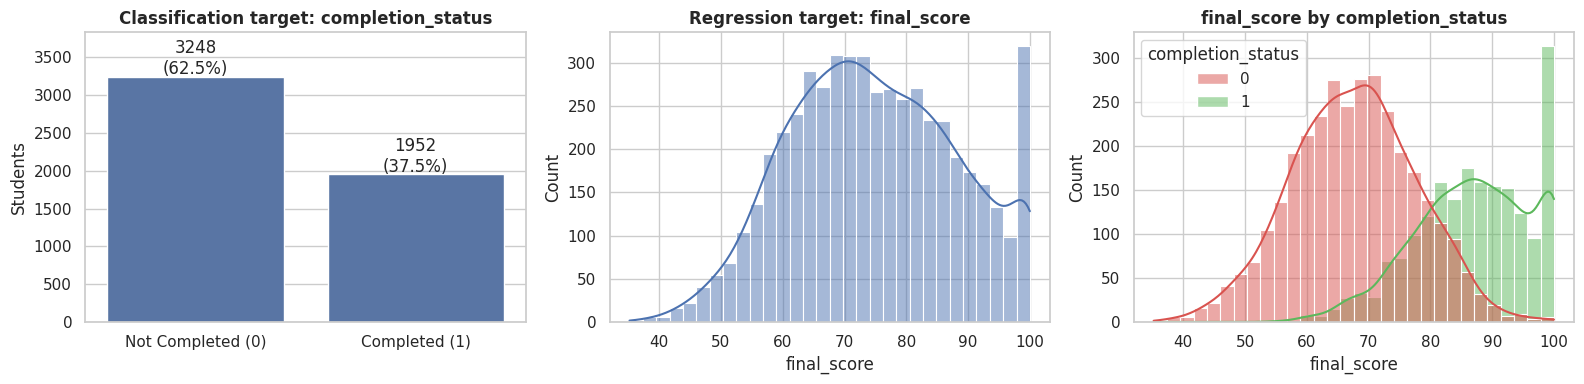

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
counts = df["completion_status"].value_counts().sort_index()
sns.barplot(x=["Not Completed (0)", "Completed (1)"], y=counts.values, ax=axes[0])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, f"{v}\n({v/len(df):.1%})", ha="center")
axes[0].set_title("Classification target: completion_status"); axes[0].set_ylabel("Students")
axes[0].set_ylim(0, counts.max() * 1.18)

sns.histplot(df["final_score"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Regression target: final_score")

sns.histplot(data=df, x="final_score", hue="completion_status", bins=30, kde=True, ax=axes[2],
             palette={0: "#d9534f", 1: "#5cb85c"})
axes[2].set_title("final_score by completion_status")
save_fig("01_target_distributions")

**Interpretation:** `final_score` is roughly bell-shaped (mean ≈ 75, range ≈ 35–100). Students who completed the course tend to score higher, but the two distributions **overlap substantially** — completion and score are related, not identical, so neither task is trivially easy.

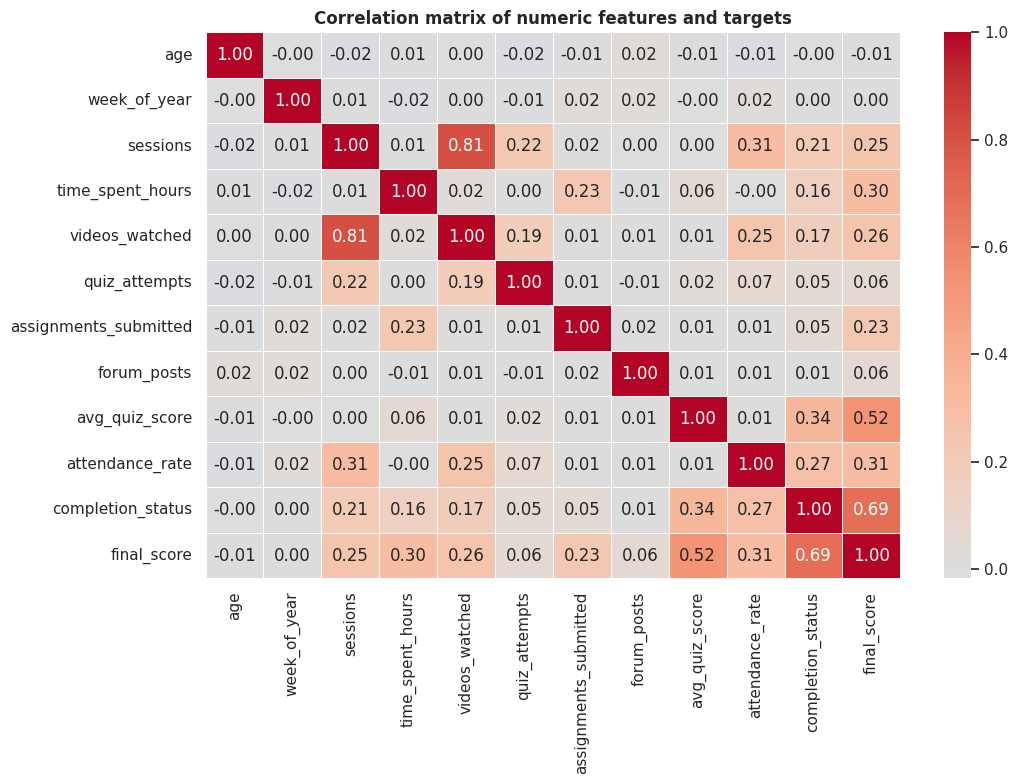

In [5]:
num_df = df.select_dtypes("number").drop(columns=["student_id"])
plt.figure(figsize=(11, 8))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation matrix of numeric features and targets")
save_fig("02_correlation_heatmap")

**Interpretation:** `avg_quiz_score` is the strongest predictor of both targets (r ≈ 0.34 with completion, 0.52 with score), followed by `attendance_rate`, `sessions`, `videos_watched` and `time_spent_hours`. Demographics (`age`, `week_of_year`) have ~0 linear correlation. ⚠️ **`completion_status` and `final_score` correlate at r ≈ 0.69** — using one as a feature for the other would be **target leakage** (see feature selection below).

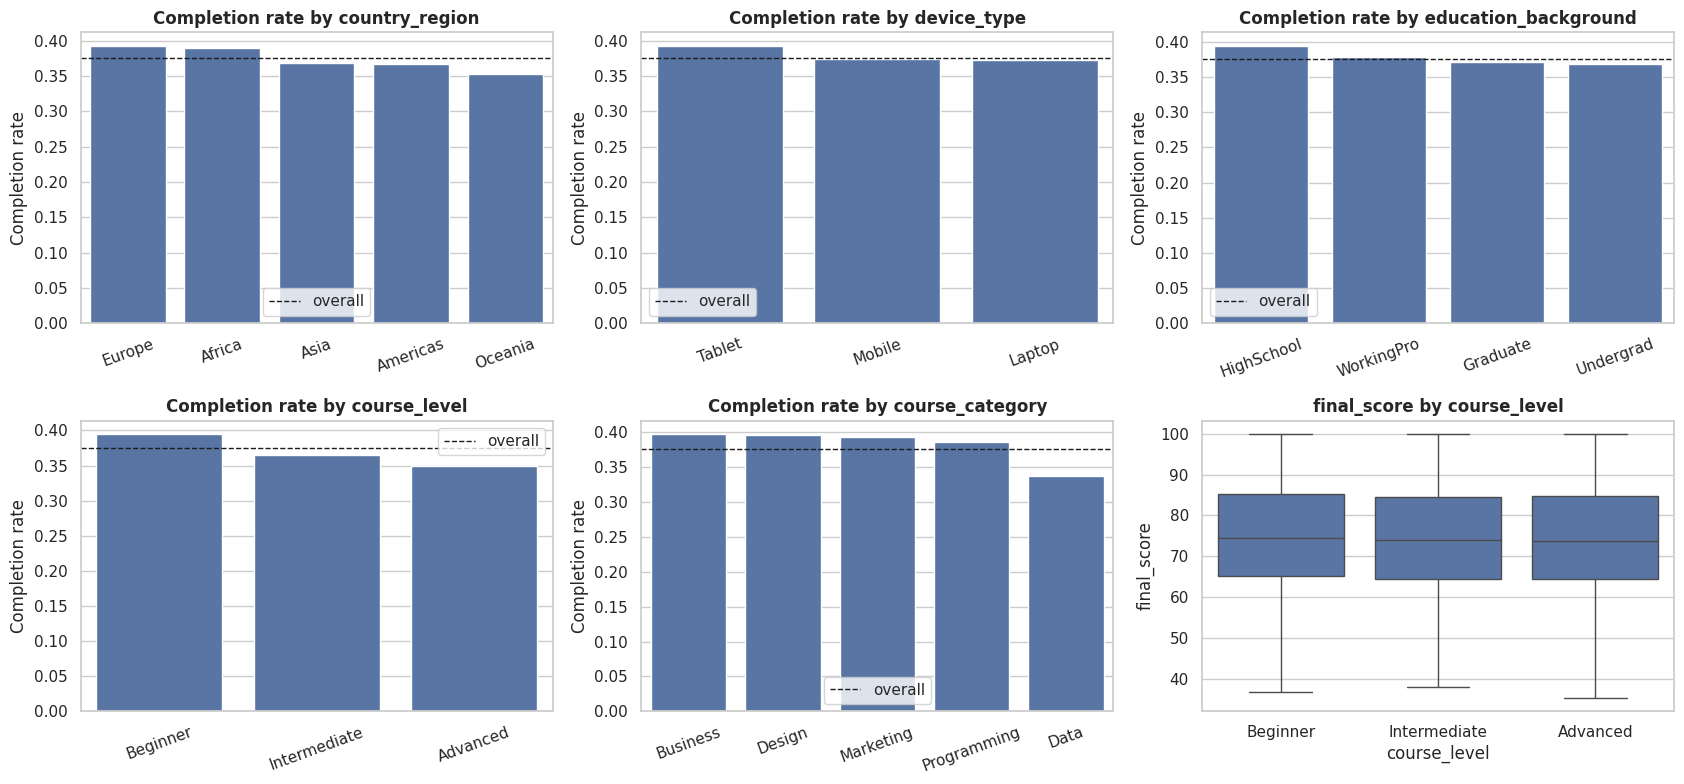

In [6]:
cat_cols_eda = ["country_region", "device_type", "education_background", "course_level", "course_category"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), cat_cols_eda):
    rate = df.groupby(c)["completion_status"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(df["completion_status"].mean(), color="k", ls="--", lw=1, label="overall")
    ax.set_title(f"Completion rate by {c}"); ax.set_ylabel("Completion rate"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20); ax.legend()
sns.boxplot(data=df, x="course_level", y="final_score", order=["Beginner", "Intermediate", "Advanced"], ax=axes[1, 2])
axes[1, 2].set_title("final_score by course_level")
save_fig("03_categorical_vs_targets")

**Interpretation:** Completion rates differ only moderately across categories (device, education, region…), meaning categorical variables carry a **weaker signal** than engagement/assessment features. Course level shifts the score distribution, so it is kept as a feature.

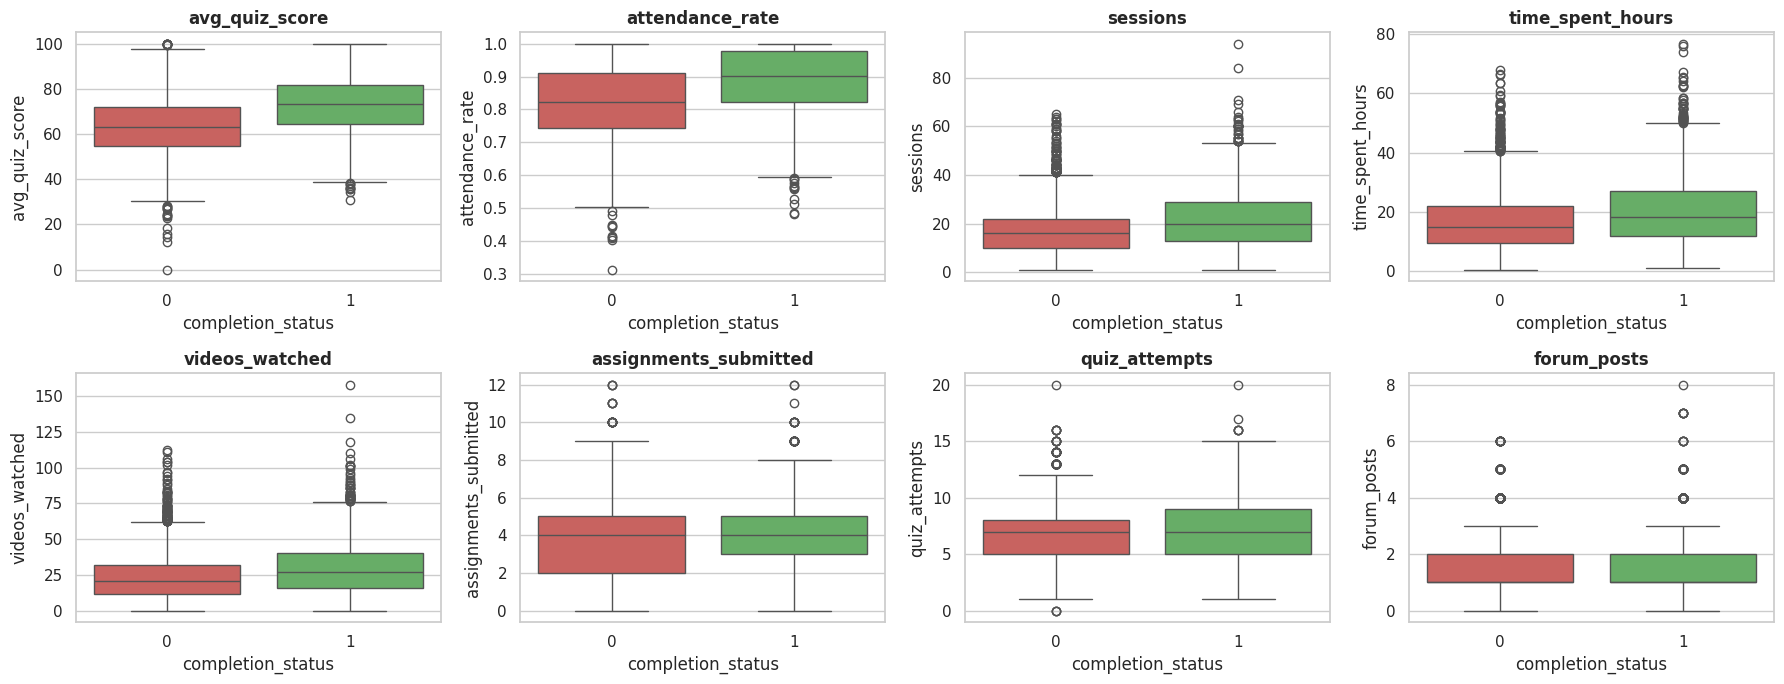

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), ["avg_quiz_score", "attendance_rate", "sessions", "time_spent_hours",
                                "videos_watched", "assignments_submitted", "quiz_attempts", "forum_posts"]):
    sns.boxplot(data=df, x="completion_status", y=c, hue="completion_status", ax=ax, palette=["#d9534f", "#5cb85c"], legend=False)
    ax.set_title(c)
save_fig("04_engagement_by_completion")

**Interpretation:** Completers have visibly higher `avg_quiz_score`, `attendance_rate`, `sessions`, `videos_watched` and `time_spent_hours`. The distributions overlap (and contain outliers), which is exactly where **non-linear, tree-based ensembles** should help over a single rigid model.

### Task 6 — Identify features and target variables
| | Classification task | Regression task |
|---|---|---|
| **Target** | `completion_status` (0/1) | `final_score` (0–100) |
| **Numeric features (10)** | `age, week_of_year, sessions, time_spent_hours, videos_watched, quiz_attempts, assignments_submitted, forum_posts, avg_quiz_score, attendance_rate` | same |
| **Categorical features (5)** | `country_region, device_type, education_background, course_level, course_category` | same |
| **Dropped** | `student_id` (identifier, no signal), `course_start_date` (raw date; the seasonal signal is already in `week_of_year`), **`final_score`** (other target → leakage) | `student_id`, `course_start_date`, **`completion_status`** (other target → leakage) |

> **Assumption (documented):** the two targets are *outcomes* of the same course. At prediction time neither is known, so each task uses **only the 15 behavioural / demographic features** and never the other target.

In [8]:
TARGET_CLF, TARGET_REG = "completion_status", "final_score"
NUM_FEATURES = ["age", "week_of_year", "sessions", "time_spent_hours", "videos_watched",
                "quiz_attempts", "assignments_submitted", "forum_posts", "avg_quiz_score", "attendance_rate"]
CAT_FEATURES = ["country_region", "device_type", "education_background", "course_level", "course_category"]
FEATURES = NUM_FEATURES + CAT_FEATURES

X = df[FEATURES].copy()
y_clf = df[TARGET_CLF].copy()
y_reg = df[TARGET_REG].copy()
print(f"{len(FEATURES)} features  |  X shape = {X.shape}")

15 features  |  X shape = (5200, 15)


### Task 7 — Train–test split
An **80 / 20 split, stratified on `completion_status`**, is applied once and shared by both tasks so that every model for both problems is evaluated on exactly the same held-out students.

In [9]:
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_clf, y_reg, test_size=0.20, stratify=y_clf, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print("Completion rate  train: %.3f | test: %.3f" % (yc_train.mean(), yc_test.mean()))
print("Mean final_score train: %.2f | test: %.2f" % (yr_train.mean(), yr_test.mean()))

Train: (4160, 15)   Test: (1040, 15)
Completion rate  train: 0.375 | test: 0.375
Mean final_score train: 74.77 | test: 75.03


### Task 8 — Basic preprocessing
* **Numeric:** median imputation → `StandardScaler` (needed by KNN / SVM / Logistic Regression; harmless for trees).
* **Categorical:** `OneHotEncoder(handle_unknown="ignore")`.
* Everything is wrapped in a `ColumnTransformer` placed **inside every model's `Pipeline`**, so imputation/scaling statistics are learned from training folds only (no data leakage, also during cross-validation) and the same pipeline can be reused directly for deployment on raw inputs.

In [10]:
def make_preprocessor():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler())])
    categorical = OneHotEncoder(handle_unknown="ignore")
    return ColumnTransformer([("num", numeric, NUM_FEATURES),
                              ("cat", categorical, CAT_FEATURES)])

prep_demo = make_preprocessor().fit(X_train)
Xt_demo = prep_demo.transform(X_train)
print("Feature matrix after preprocessing:", Xt_demo.shape)
print("Missing values after preprocessing:", int(np.isnan(Xt_demo).sum()))
print("First feature names:", list(prep_demo.get_feature_names_out()[:6]), "...")

Feature matrix after preprocessing: (4160, 30)
Missing values after preprocessing: 0
First feature names: ['num__age', 'num__week_of_year', 'num__sessions', 'num__time_spent_hours', 'num__videos_watched', 'num__quiz_attempts'] ...


### Evaluation helpers
Reusable functions train a model inside a pipeline, compute **train and test** metrics, and register the fitted model so Part F can compare everything in one table.

* Classification: Accuracy, Precision, Recall, F1, ROC-AUC (positive class = Completed).
* Regression: MAE, RMSE, R².
* Train metrics are kept as well to quantify **over-fitting** (train–test gap), which is central to the bagging / boosting discussion.

In [11]:
clf_results, reg_results = [], []
clf_models, reg_models = {}, {}
clf_proba, reg_pred = {}, {}

def fit_eval_clf(name, family, estimator):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", estimator)])
    t0 = time.time(); pipe.fit(X_train, yc_train); fit_time = time.time() - t0
    pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        proba = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(yc_test, proba)
        train_auc = roc_auc_score(yc_train, pipe.predict_proba(X_train)[:, 1])
        clf_proba[name] = proba
    else:                       # hard voting has no probabilities -> AUC from class labels
        auc = roc_auc_score(yc_test, pred)
        train_auc = roc_auc_score(yc_train, pipe.predict(X_train))
    row = {"Model": name, "Family": family,
           "Accuracy": accuracy_score(yc_test, pred),
           "Precision": precision_score(yc_test, pred),
           "Recall": recall_score(yc_test, pred),
           "F1": f1_score(yc_test, pred),
           "ROC-AUC": auc, "Train ROC-AUC": train_auc, "Fit time (s)": fit_time}
    clf_results.append(row); clf_models[name] = pipe
    print(f"[CLF] {name:<26} Acc={row['Accuracy']:.3f}  Prec={row['Precision']:.3f}  "
          f"Rec={row['Recall']:.3f}  F1={row['F1']:.3f}  AUC={auc:.3f}  (train AUC={train_auc:.3f})")
    return pipe

def fit_eval_reg(name, family, estimator):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", estimator)])
    t0 = time.time(); pipe.fit(X_train, yr_train); fit_time = time.time() - t0
    pred = pipe.predict(X_test)
    rmse = np.sqrt(mean_squared_error(yr_test, pred))
    train_rmse = np.sqrt(mean_squared_error(yr_train, pipe.predict(X_train)))
    row = {"Model": name, "Family": family,
           "MAE": mean_absolute_error(yr_test, pred), "RMSE": rmse, "R²": r2_score(yr_test, pred),
           "Train RMSE": train_rmse, "Fit time (s)": fit_time}
    reg_results.append(row); reg_models[name] = pipe; reg_pred[name] = pred
    print(f"[REG] {name:<26} MAE={row['MAE']:.3f}  RMSE={rmse:.3f}  R²={row['R²']:.3f}  (train RMSE={train_rmse:.3f})")
    return pipe

# --- cross-validation (robustness) helper, results cached ---
cv_cache = {"clf": {}, "reg": {}}
def cv_robustness(task, names):
    for n in names:
        if n in cv_cache[task]:
            continue
        if task == "clf":
            if n == "Voting (hard)":      # no probabilities -> no ROC-AUC
                continue
            s = cross_val_score(clone(clf_models[n]), X_train, yc_train, scoring="roc_auc",
                                cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
        else:
            s = -cross_val_score(clone(reg_models[n]), X_train, yr_train, scoring="neg_root_mean_squared_error",
                                 cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
        cv_cache[task][n] = s
    rows = [{"Model": n, "CV mean": cv_cache[task][n].mean(), "CV std": cv_cache[task][n].std()}
            for n in names if n in cv_cache[task]]
    return pd.DataFrame(rows).set_index("Model")
print("Helpers ready ✔")

Helpers ready ✔


---
# 📦 Part C: Bagging (Bootstrap Aggregating)

**Idea:** train many copies of a high-variance learner (a decision tree) on bootstrap resamples of the training set and **average / vote** their outputs. We first build the **single base model** (a depth-8 decision tree) so that Task 11's comparison is *like-for-like* — the bagged ensembles use exactly the same base tree.

In [12]:
# Single base models (the baseline for Task 11)
fit_eval_clf("Decision Tree (single)", "Single", DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE))
fit_eval_reg("Decision Tree (single)", "Single", DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE))

[CLF] Decision Tree (single)     Acc=0.679  Prec=0.580  Rec=0.521  F1=0.549  AUC=0.712  (train AUC=0.884)


[REG] Decision Tree (single)     MAE=9.239  RMSE=11.565  R²=0.265  (train RMSE=8.418)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

### Task 9 — Bagging Classifier (course completion)

In [13]:
bag_clf = fit_eval_clf("Bagging", "Bagging", BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    n_estimators=200, max_samples=1.0, bootstrap=True, oob_score=True,
    n_jobs=-1, random_state=RANDOM_STATE))
print("\nOut-of-bag accuracy (free validation estimate): %.3f" % bag_clf.named_steps["model"].oob_score_)

[CLF] Bagging                    Acc=0.725  Prec=0.657  Rec=0.559  F1=0.604  AUC=0.778  (train AUC=0.938)

Out-of-bag accuracy (free validation estimate): 0.715


### Task 10 — Bagging Regressor (final score)

In [14]:
bag_reg = fit_eval_reg("Bagging", "Bagging", BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    n_estimators=200, max_samples=1.0, bootstrap=True, oob_score=True,
    n_jobs=-1, random_state=RANDOM_STATE))
print("\nOut-of-bag R²: %.3f" % bag_reg.named_steps["model"].oob_score_)

[REG] Bagging                    MAE=8.229  RMSE=10.241  R²=0.424  (train RMSE=7.696)

Out-of-bag R²: 0.469


### Task 11 — Bagging vs. a single base model

Classification: single tree vs bagging


,Accuracy,Precision,Recall,F1,ROC-AUC,Train ROC-AUC
Model,,,,,,
Decision Tree (single),0.6788,0.5800,0.5205,0.5486,0.7116,0.8836
Bagging,0.7250,0.6566,0.5590,0.6039,0.7775,0.9380


Regression: single tree vs bagging


,MAE,RMSE,R²,Train RMSE
Model,,,,
Decision Tree (single),9.2390,11.5655,0.2652,8.4177
Bagging,8.2288,10.2412,0.4239,7.6958


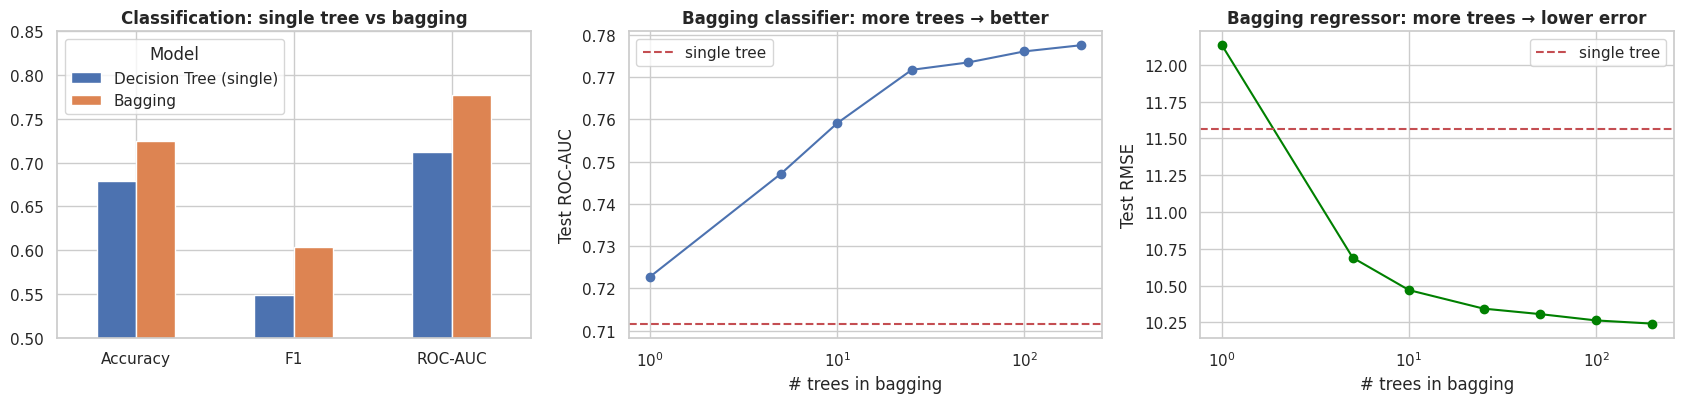

In [15]:
cmp_clf = pd.DataFrame(clf_results).set_index("Model").loc[["Decision Tree (single)", "Bagging"],
          ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Train ROC-AUC"]]
cmp_reg = pd.DataFrame(reg_results).set_index("Model").loc[["Decision Tree (single)", "Bagging"],
          ["MAE", "RMSE", "R²", "Train RMSE"]]
print("Classification: single tree vs bagging"); display(cmp_clf.round(4))
print("Regression: single tree vs bagging");     display(cmp_reg.round(4))

# Effect of the number of bagged trees
Xtr_p = make_preprocessor().fit(X_train); Xte_p = Xtr_p.transform(X_test); Xtr_p = Xtr_p.transform(X_train)
n_list = [1, 5, 10, 25, 50, 100, 200]
auc_curve, rmse_curve = [], []
for n in n_list:
    c = BaggingClassifier(DecisionTreeClassifier(max_depth=8), n_estimators=n, n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr_p, yc_train)
    auc_curve.append(roc_auc_score(yc_test, c.predict_proba(Xte_p)[:, 1]))
    r = BaggingRegressor(DecisionTreeRegressor(max_depth=8), n_estimators=n, n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr_p, yr_train)
    rmse_curve.append(np.sqrt(mean_squared_error(yr_test, r.predict(Xte_p))))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
metrics_c = cmp_clf[["Accuracy", "F1", "ROC-AUC"]].T
metrics_c.plot(kind="bar", ax=axes[0], rot=0); axes[0].set_title("Classification: single tree vs bagging"); axes[0].set_ylim(0.5, 0.85)
axes[1].plot(n_list, auc_curve, "o-"); axes[1].axhline(cmp_clf.loc["Decision Tree (single)", "ROC-AUC"], color="r", ls="--", label="single tree")
axes[1].set_xscale("log"); axes[1].set_xlabel("# trees in bagging"); axes[1].set_ylabel("Test ROC-AUC"); axes[1].set_title("Bagging classifier: more trees → better"); axes[1].legend()
axes[2].plot(n_list, rmse_curve, "o-", color="green"); axes[2].axhline(cmp_reg.loc["Decision Tree (single)", "RMSE"], color="r", ls="--", label="single tree")
axes[2].set_xscale("log"); axes[2].set_xlabel("# trees in bagging"); axes[2].set_ylabel("Test RMSE"); axes[2].set_title("Bagging regressor: more trees → lower error"); axes[2].legend()
save_fig("05_bagging_vs_single")

**Interpretation — Bagging vs single model:** with the *same* base tree, bagging improves every test metric for both tasks (e.g. ROC-AUC 0.71 → 0.78, RMSE 11.6 → 10.2) and **narrows the train–test gap** (modestly for classification, clearly for regression). The curves show the textbook variance-reduction effect: error drops quickly over the first ~25–50 trees and then plateaus, so adding more trees never hurts but gives diminishing returns. The out-of-bag estimates (accuracy ≈ 0.72, R² ≈ 0.47) are a free validation signal that is broadly consistent with the held-out test set.

---
# ⚡ Part D: Boosting Algorithms
## AdaBoost
**Idea:** weak learners (shallow trees) are trained **sequentially**; after each round misclassified samples (or high-error samples for regression) receive more weight, so the next learner concentrates on the hard cases. Final prediction = weighted vote/sum of learners.

### Task 12 — AdaBoost Classifier

In [16]:
ada_clf = fit_eval_clf("AdaBoost", "Boosting", AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    n_estimators=200, learning_rate=0.1, random_state=RANDOM_STATE))

[CLF] AdaBoost                   Acc=0.733  Prec=0.685  Rec=0.531  F1=0.598  AUC=0.789  (train AUC=0.800)


### Task 13 — AdaBoost Regressor

In [17]:
ada_reg = fit_eval_reg("AdaBoost", "Boosting", AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    n_estimators=200, learning_rate=0.1, random_state=RANDOM_STATE))

[REG] AdaBoost                   MAE=8.606  RMSE=10.572  R²=0.386  (train RMSE=10.007)


### Task 14 — How do weak learners improve sequentially?
We (a) track test performance after each boosting round using `staged_predict*`, comparing against a **single weak learner** (the first stump/shallow tree), and (b) inspect each learner's weighted training error and its voting weight (`estimator_errors_`, `estimator_weights_`).

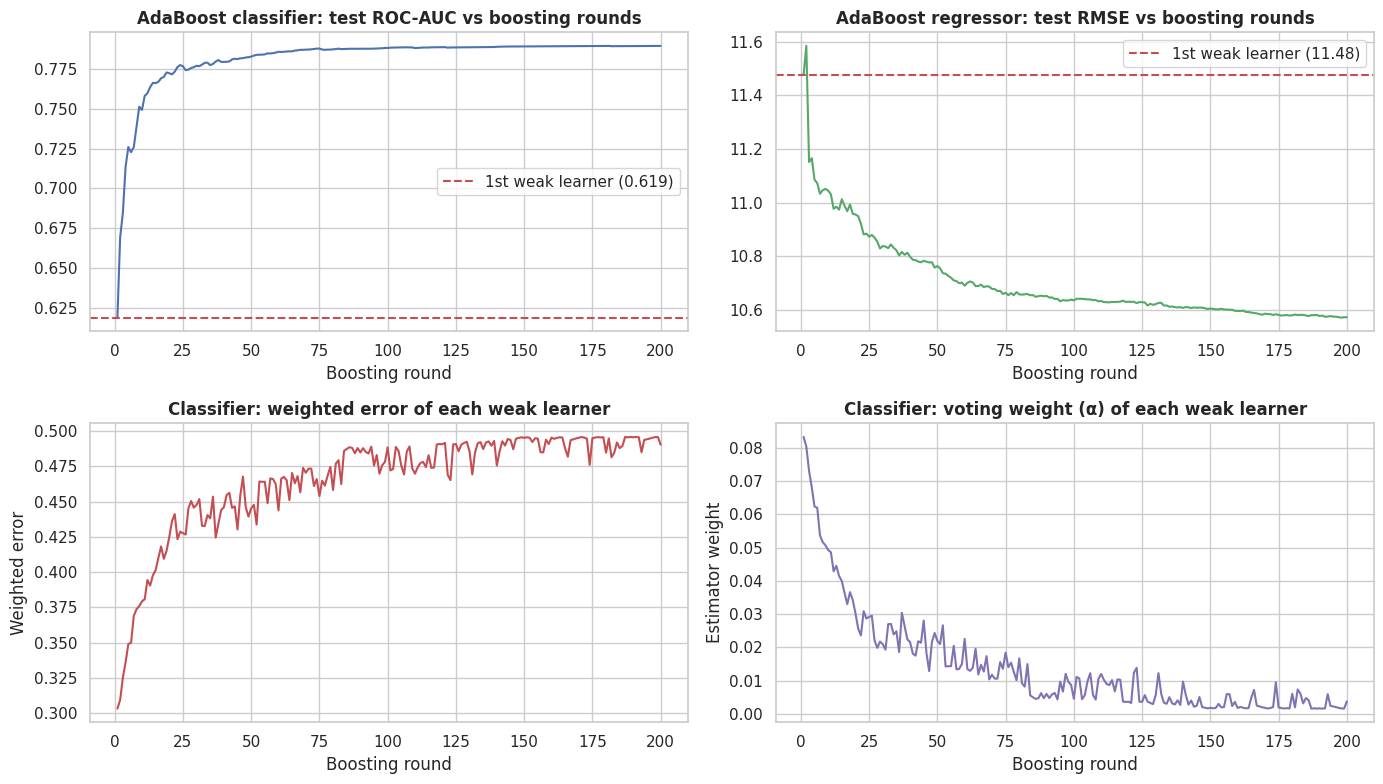

Classifier ROC-AUC: round 1 = 0.619  →  round 200 = 0.789   (best at round 199: 0.789)
Classifier accuracy: round 1 = 0.690  →  round 200 = 0.733
Regressor  RMSE   : round 1 = 11.48  →  round 200 = 10.57   (best at round 198: 10.57)


In [18]:
prep_fit = ada_clf.named_steps["prep"]
Xte_a = prep_fit.transform(X_test)
ada_c = ada_clf.named_steps["model"]; ada_r = ada_reg.named_steps["model"]

# (a) staged performance
staged_auc = [roc_auc_score(yc_test, p[:, 1]) for p in ada_c.staged_predict_proba(Xte_a)]
staged_rmse = [np.sqrt(mean_squared_error(yr_test, p)) for p in ada_r.staged_predict(Xte_a)]
staged_acc = [accuracy_score(yc_test, p) for p in ada_c.staged_predict(Xte_a)]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(range(1, len(staged_auc) + 1), staged_auc, color="C0")
axes[0, 0].axhline(staged_auc[0], color="r", ls="--", label=f"1st weak learner ({staged_auc[0]:.3f})")
axes[0, 0].set_title("AdaBoost classifier: test ROC-AUC vs boosting rounds"); axes[0, 0].set_xlabel("Boosting round"); axes[0, 0].legend()
axes[0, 1].plot(range(1, len(staged_rmse) + 1), staged_rmse, color="C2")
axes[0, 1].axhline(staged_rmse[0], color="r", ls="--", label=f"1st weak learner ({staged_rmse[0]:.2f})")
axes[0, 1].set_title("AdaBoost regressor: test RMSE vs boosting rounds"); axes[0, 1].set_xlabel("Boosting round"); axes[0, 1].legend()

# (b) learner errors and weights (classifier)
k = len(ada_c.estimator_errors_)
axes[1, 0].plot(range(1, k + 1), ada_c.estimator_errors_, color="C3")
axes[1, 0].set_title("Classifier: weighted error of each weak learner"); axes[1, 0].set_xlabel("Boosting round"); axes[1, 0].set_ylabel("Weighted error")
axes[1, 1].plot(range(1, k + 1), ada_c.estimator_weights_, color="C4")
axes[1, 1].set_title("Classifier: voting weight (α) of each weak learner"); axes[1, 1].set_xlabel("Boosting round"); axes[1, 1].set_ylabel("Estimator weight")
save_fig("06_adaboost_sequential_learning")

print(f"Classifier ROC-AUC: round 1 = {staged_auc[0]:.3f}  →  round 200 = {staged_auc[-1]:.3f}   (best at round {int(np.argmax(staged_auc))+1}: {max(staged_auc):.3f})")
print(f"Classifier accuracy: round 1 = {staged_acc[0]:.3f}  →  round 200 = {staged_acc[-1]:.3f}")
print(f"Regressor  RMSE   : round 1 = {staged_rmse[0]:.2f}  →  round 200 = {staged_rmse[-1]:.2f}   (best at round {int(np.argmin(staged_rmse))+1}: {min(staged_rmse):.2f})")

**Interpretation:** a *single* weak learner performs poorly (it is deliberately simple); as rounds are added the ensemble's ROC-AUC rises from ≈ 0.62 to ≈ 0.79 (plateauing after ~75 rounds) and RMSE falls from ≈ 11.5 to ≈ 10.6 (still creeping down at round 200) — each new learner contributes less because the "easy" structure has already been captured and what remains is mostly noise. The weighted error of each learner **rises from ≈ 0.30 towards 0.5** as boosting progresses (the remaining hard samples carry most of the weight, so every new weak learner finds them hard), and the learner weights α shrink accordingly. This is exactly the sequential error-correction behaviour of AdaBoost, and the small `learning_rate=0.1` keeps the contribution of each learner modest, which acts as regularisation.

## XGBoost

### Task 15 — XGBoost Classifier  |  Task 16 — XGBoost Regressor

In [19]:
xgb_params = dict(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                  colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1)
xgb_clf = fit_eval_clf("XGBoost", "Boosting", XGBClassifier(eval_metric="logloss", **xgb_params))
xgb_reg = fit_eval_reg("XGBoost", "Boosting", XGBRegressor(**xgb_params))

[CLF] XGBoost                    Acc=0.731  Prec=0.660  Rec=0.582  F1=0.619  AUC=0.780  (train AUC=0.859)
[REG] XGBoost                    MAE=8.155  RMSE=10.170  R²=0.432  (train RMSE=8.556)


For a fair "compare with other boosting models" (Task 17) we add **scikit-learn Gradient Boosting** (the classic non-regularised GBM) and a **randomised-search-tuned XGBoost** (3-fold CV on the *training* set only).

In [20]:
fit_eval_clf("Gradient Boosting", "Boosting", GradientBoostingClassifier(random_state=RANDOM_STATE))
fit_eval_reg("Gradient Boosting", "Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE))

param_dist = {"model__n_estimators": [100, 200, 300, 500],
              "model__max_depth": [2, 3, 4, 5],
              "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
              "model__subsample": [0.6, 0.8, 1.0],
              "model__colsample_bytree": [0.6, 0.8, 1.0],
              "model__min_child_weight": [1, 3, 5, 10],
              "model__reg_lambda": [0.5, 1, 5, 10]}

t0 = time.time()
search_c = RandomizedSearchCV(
    Pipeline([("prep", make_preprocessor()), ("model", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1))]),
    param_dist, n_iter=20, cv=3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=1).fit(X_train, yc_train)
search_r = RandomizedSearchCV(
    Pipeline([("prep", make_preprocessor()), ("model", XGBRegressor(random_state=RANDOM_STATE, n_jobs=1))]),
    param_dist, n_iter=20, cv=3, scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1).fit(X_train, yr_train)
print(f"Tuning finished in {time.time()-t0:.0f}s")
print("Best XGB classifier params:", {k.replace('model__',''): v for k, v in search_c.best_params_.items()})
print("Best XGB regressor  params:", {k.replace('model__',''): v for k, v in search_r.best_params_.items()})

best_xc = {k.replace("model__", ""): v for k, v in search_c.best_params_.items()}
best_xr = {k.replace("model__", ""): v for k, v in search_r.best_params_.items()}
fit_eval_clf("XGBoost (tuned)", "Boosting", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1, **best_xc))
fit_eval_reg("XGBoost (tuned)", "Boosting", XGBRegressor(random_state=RANDOM_STATE, n_jobs=1, **best_xr))

[CLF] Gradient Boosting          Acc=0.738  Prec=0.676  Rec=0.582  F1=0.625  AUC=0.788  (train AUC=0.846)


[REG] Gradient Boosting          MAE=8.207  RMSE=10.200  R²=0.429  (train RMSE=8.763)


Tuning finished in 19s
Best XGB classifier params: {'subsample': 0.6, 'reg_lambda': 0.5, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best XGB regressor  params: {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


[CLF] XGBoost (tuned)            Acc=0.742  Prec=0.684  Rec=0.582  F1=0.629  AUC=0.788  (train AUC=0.820)
[REG] XGBoost (tuned)            MAE=8.131  RMSE=10.123  R²=0.437  (train RMSE=9.124)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

### Task 17 — Performance and robustness of XGBoost vs the other boosting models

5-fold CV finished in 23s
Boosting comparison — classification


,Accuracy,F1,ROC-AUC,Train ROC-AUC,Fit time (s),CV AUC mean,CV AUC std
Model,,,,,,,
AdaBoost,0.7327,0.5983,0.7894,0.8004,1.3122,0.7745,0.0095
Gradient Boosting,0.7385,0.6253,0.7880,0.8457,0.7646,0.7707,0.0079
XGBoost,0.7308,0.6185,0.7798,0.8588,0.2035,0.7714,0.0075
XGBoost (tuned),0.7423,0.6288,0.7883,0.8198,0.2725,0.7804,0.0090


Boosting comparison — regression


,MAE,RMSE,R²,Train RMSE,Fit time (s),CV RMSE mean,CV RMSE std
Model,,,,,,,
AdaBoost,8.6062,10.5721,0.3860,10.0068,1.8162,10.2677,0.1153
Gradient Boosting,8.2072,10.1998,0.4285,8.7635,0.7439,9.7011,0.1205
XGBoost,8.1554,10.1702,0.4318,8.5556,0.1394,9.7084,0.1459
XGBoost (tuned),8.1311,10.1229,0.4371,9.1243,0.1523,9.6259,0.1178


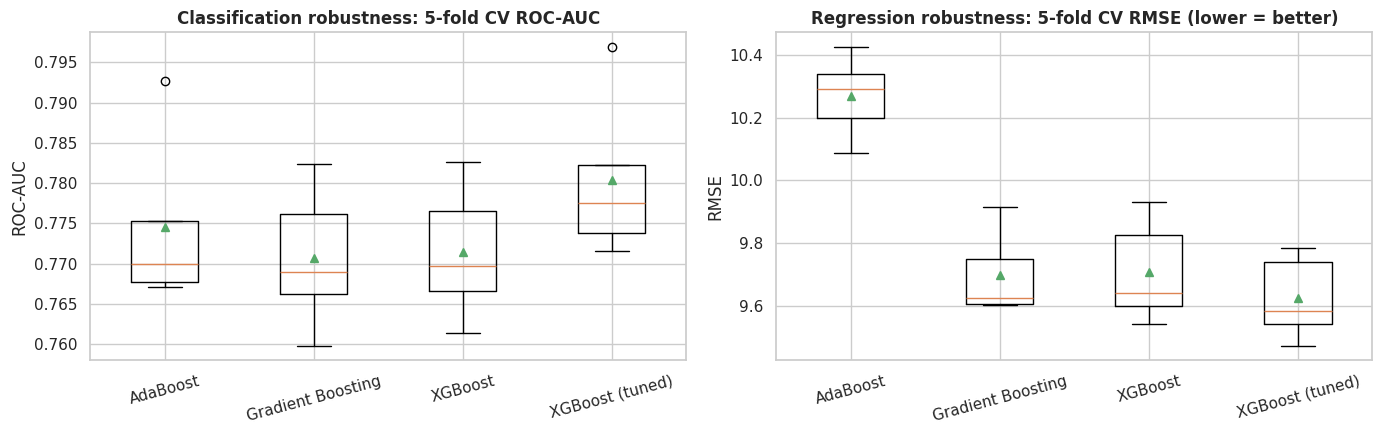

In [21]:
boost_names = ["AdaBoost", "Gradient Boosting", "XGBoost", "XGBoost (tuned)"]
t0 = time.time()
cv_c = cv_robustness("clf", boost_names); cv_r = cv_robustness("reg", boost_names)
print(f"5-fold CV finished in {time.time()-t0:.0f}s")

bc = pd.DataFrame(clf_results).set_index("Model").loc[boost_names]
br = pd.DataFrame(reg_results).set_index("Model").loc[boost_names]
tab_c = bc[["Accuracy", "F1", "ROC-AUC", "Train ROC-AUC", "Fit time (s)"]].join(cv_c.rename(columns={"CV mean": "CV AUC mean", "CV std": "CV AUC std"}))
tab_r = br[["MAE", "RMSE", "R²", "Train RMSE", "Fit time (s)"]].join(cv_r.rename(columns={"CV mean": "CV RMSE mean", "CV std": "CV RMSE std"}))
print("Boosting comparison — classification"); display(tab_c.round(4))
print("Boosting comparison — regression");     display(tab_r.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot([cv_cache["clf"][n] for n in boost_names], labels=boost_names, showmeans=True)
axes[0].set_title("Classification robustness: 5-fold CV ROC-AUC"); axes[0].set_ylabel("ROC-AUC"); axes[0].tick_params(axis="x", rotation=15)
axes[1].boxplot([cv_cache["reg"][n] for n in boost_names], labels=boost_names, showmeans=True)
axes[1].set_title("Regression robustness: 5-fold CV RMSE (lower = better)"); axes[1].set_ylabel("RMSE"); axes[1].tick_params(axis="x", rotation=15)
save_fig("07_boosting_robustness_cv")

**Interpretation:** the four boosting models land in a **narrow performance band** (the data are noisy, so there is a ceiling on achievable accuracy). The regularised, gradient-based methods (Gradient Boosting, XGBoost, tuned XGBoost) are at least as good as AdaBoost on regression and similar on classification, and are **faster** (XGBoost trains in a fraction of a second) — the small CV standard deviations show all of them are stable across folds. Tuning XGBoost gives a modest, not dramatic, gain: the remaining error is largely irreducible noise rather than model capacity.

---
# 🗳️ Part E: Voting & Stacking Ensembles
Voting and stacking combine **different algorithms**, so we first evaluate the individual base learners that go into them (decision tree already done above).

In [22]:
fit_eval_clf("Logistic Regression", "Base learner", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
fit_eval_clf("KNN", "Base learner", KNeighborsClassifier(n_neighbors=25))
fit_eval_clf("SVC", "Base learner", SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE))
print()
fit_eval_reg("Ridge", "Base learner", Ridge(alpha=1.0))
fit_eval_reg("KNN", "Base learner", KNeighborsRegressor(n_neighbors=25))
fit_eval_reg("SVR", "Base learner", SVR(kernel="rbf", C=10.0))

[CLF] Logistic Regression        Acc=0.745  Prec=0.687  Rec=0.590  F1=0.634  AUC=0.794  (train AUC=0.791)


[CLF] KNN                        Acc=0.697  Prec=0.657  Rec=0.403  F1=0.499  AUC=0.751  (train AUC=0.795)


[CLF] SVC                        Acc=0.729  Prec=0.673  Rec=0.538  F1=0.598  AUC=0.764  (train AUC=0.871)

[REG] Ridge                      MAE=8.084  RMSE=10.045  R²=0.446  (train RMSE=9.470)


[REG] KNN                        MAE=8.641  RMSE=10.638  R²=0.378  (train RMSE=9.912)


[REG] SVR                        MAE=8.307  RMSE=10.394  R²=0.407  (train RMSE=8.139)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

### Tasks 18 & 19 — Voting Classifier: Hard vs Soft voting

[CLF] Voting (hard)              Acc=0.728  Prec=0.711  Rec=0.462  F1=0.560  AUC=0.675  (train AUC=0.699)


[CLF] Voting (soft)              Acc=0.729  Prec=0.682  Rec=0.518  F1=0.589  AUC=0.785  (train AUC=0.834)


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7452,0.6866,0.5897,0.6345,0.7939
KNN,0.6971,0.6569,0.4026,0.4992,0.7514
SVC,0.7288,0.6731,0.5385,0.5983,0.7635
Voting (hard),0.7279,0.7115,0.4615,0.5599,0.6746
Voting (soft),0.7288,0.6824,0.5179,0.5889,0.7852


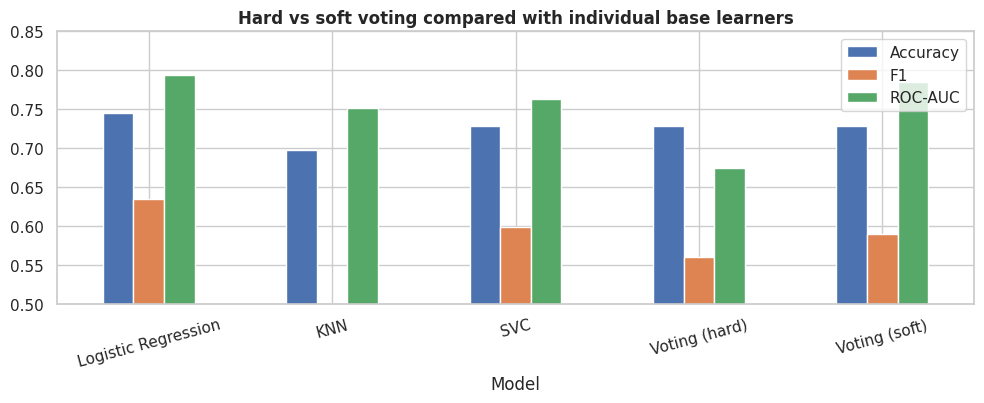

In [23]:
def voting_base_clf():
    return [("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
            ("knn", KNeighborsClassifier(n_neighbors=25)),
            ("dt", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)),
            ("svc", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]

fit_eval_clf("Voting (hard)", "Voting", VotingClassifier(voting_base_clf(), voting="hard"))
fit_eval_clf("Voting (soft)", "Voting", VotingClassifier(voting_base_clf(), voting="soft"))

vt = pd.DataFrame(clf_results).set_index("Model").loc[
     ["Logistic Regression", "KNN", "SVC", "Voting (hard)", "Voting (soft)"], ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
display(vt.round(4))
vt[["Accuracy", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(10, 4.2), rot=15)
plt.title("Hard vs soft voting compared with individual base learners"); plt.ylim(0.5, 0.85)
save_fig("08_hard_vs_soft_voting")

**Interpretation — Hard vs Soft voting:** soft voting uses the *confidence* of every model, hard voting throws that away and counts only the final labels. Soft voting therefore gives a proper probability ranking (a real ROC-AUC; for hard voting the "AUC" is computed from 0/1 labels and is not directly comparable) and typically scores equal or higher than hard voting, particularly in F1/recall, because a confident model can outweigh several uncertain ones. Both are limited by the quality of their weakest members (the shallow decision tree and KNN here): soft voting (ROC-AUC ≈ 0.785) ends up slightly *below* its best member, Logistic Regression (≈ 0.794), which shows that voting does not automatically beat its strongest ingredient when the members' errors are highly correlated.

### Task 20 — Stacking Classifier with a meta-learner

In [24]:
stack_clf = fit_eval_clf("Stacking", "Stacking", StackingClassifier(
    estimators=[("rf", RandomForestClassifier(n_estimators=100, max_depth=8, random_state=RANDOM_STATE)),
                ("xgb", XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8,
                                      colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
                ("ada", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=100,
                                           learning_rate=0.1, random_state=RANDOM_STATE)),
                ("knn", KNeighborsClassifier(n_neighbors=25))],
    final_estimator=LogisticRegression(max_iter=2000), stack_method="predict_proba", cv=5, n_jobs=1))

[CLF] Stacking                   Acc=0.738  Prec=0.686  Rec=0.559  F1=0.616  AUC=0.787  (train AUC=0.854)


### Task 21 — Stacking Regressor for score prediction (+ Voting Regressor for completeness)

In [25]:
fit_eval_reg("Voting", "Voting", VotingRegressor([
    ("ridge", Ridge(alpha=1.0)), ("knn", KNeighborsRegressor(n_neighbors=25)),
    ("dt", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)), ("svr", SVR(kernel="rbf", C=10.0))]))

stack_reg = fit_eval_reg("Stacking", "Stacking", StackingRegressor(
    estimators=[("rf", RandomForestRegressor(n_estimators=100, max_depth=8, random_state=RANDOM_STATE)),
                ("xgb", XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8,
                                     colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1)),
                ("ada", AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3), n_estimators=100,
                                          learning_rate=0.1, random_state=RANDOM_STATE)),
                ("knn", KNeighborsRegressor(n_neighbors=25))],
    final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=1))

[REG] Voting                     MAE=8.165  RMSE=10.124  R²=0.437  (train RMSE=8.989)


[REG] Stacking                   MAE=8.124  RMSE=10.121  R²=0.437  (train RMSE=8.978)


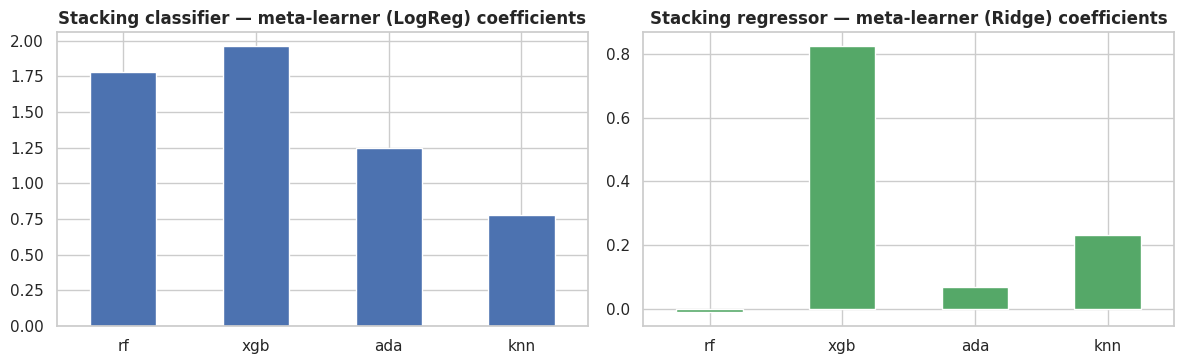

Classifier meta weights: {'rf': 1.782, 'xgb': 1.962, 'ada': 1.249, 'knn': 0.781}
Regressor meta weights : {'rf': -0.012, 'xgb': 0.827, 'ada': 0.069, 'knn': 0.23}


In [26]:
# What did the meta-learners learn? (how much each base model is trusted)
meta_c = stack_clf.named_steps["model"]; meta_r = stack_reg.named_steps["model"]
w_c = pd.Series(meta_c.final_estimator_.coef_.ravel(), index=[n for n, _ in meta_c.estimators])
w_r = pd.Series(meta_r.final_estimator_.coef_.ravel(), index=[n for n, _ in meta_r.estimators])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
w_c.plot(kind="bar", ax=axes[0], rot=0, color="C0"); axes[0].set_title("Stacking classifier — meta-learner (LogReg) coefficients")
w_r.plot(kind="bar", ax=axes[1], rot=0, color="C2"); axes[1].set_title("Stacking regressor — meta-learner (Ridge) coefficients")
save_fig("09_stacking_meta_learner_weights")
print("Classifier meta weights:", w_c.round(3).to_dict()); print("Regressor meta weights :", w_r.round(3).to_dict())

**Interpretation:** the meta-learner *learns* a trust level for every base model instead of giving each an equal vote. Larger positive coefficients mean the base model's out-of-fold predictions were more useful; near-zero or negative coefficients mean the model was redundant given the others. This learned weighting is the key advantage of stacking over voting — at the cost of more training time and a more complex model.

---
# 📊 Part F: Model Evaluation & Comparison
## Classification models (Task 22)
Metrics on the **held-out test set**: Accuracy, Precision, Recall, F1, ROC-AUC. Robustness is checked with **5-fold CV on the training set**.

In [27]:
clf_df = pd.DataFrame(clf_results).set_index("Model")
ens_clf_names = ["Decision Tree (single)", "Bagging", "AdaBoost", "Gradient Boosting", "XGBoost",
                 "XGBoost (tuned)", "Voting (hard)", "Voting (soft)", "Stacking"]
t0 = time.time()
cv_all_c = cv_robustness("clf", ens_clf_names + ["Logistic Regression"])
print(f"5-fold CV finished in {time.time()-t0:.0f}s")

clf_table = clf_df.loc[ens_clf_names + ["Logistic Regression"]].join(
    cv_all_c.rename(columns={"CV mean": "CV ROC-AUC mean", "CV std": "CV ROC-AUC std"}))
clf_table = clf_table.sort_values("ROC-AUC", ascending=False)
clf_table.round(4).to_csv("outputs/classification_results.csv")
display(clf_table.drop(columns=["Fit time (s)"]).round(4).style.background_gradient(
    cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "CV ROC-AUC mean"]))

5-fold CV finished in 54s


,Family,Accuracy,Precision,Recall,F1,ROC-AUC,Train ROC-AUC,CV ROC-AUC mean,CV ROC-AUC std
Model,,,,,,,,,
Logistic Regression,Base learner,0.745200,0.686600,0.589700,0.634500,0.793900,0.790700,0.785100,0.009200
AdaBoost,Boosting,0.732700,0.685400,0.530800,0.598300,0.789400,0.800400,0.774500,0.009500
XGBoost (tuned),Boosting,0.742300,0.683700,0.582100,0.628800,0.788300,0.819800,0.780400,0.009000
Gradient Boosting,Boosting,0.738500,0.675600,0.582100,0.625300,0.788000,0.845700,0.770700,0.007900
Stacking,Stacking,0.738500,0.685500,0.559000,0.615800,0.786800,0.854400,0.778600,0.010600
Voting (soft),Voting,0.728800,0.682400,0.517900,0.588900,0.785200,0.833600,0.776100,0.010300
XGBoost,Boosting,0.730800,0.659900,0.582100,0.618500,0.779800,0.858800,0.771400,0.007500
Bagging,Bagging,0.725000,0.656600,0.559000,0.603900,0.777500,0.938000,0.770000,0.011700
Decision Tree (single),Single,0.678800,0.580000,0.520500,0.548600,0.711600,0.883600,0.696400,0.014600


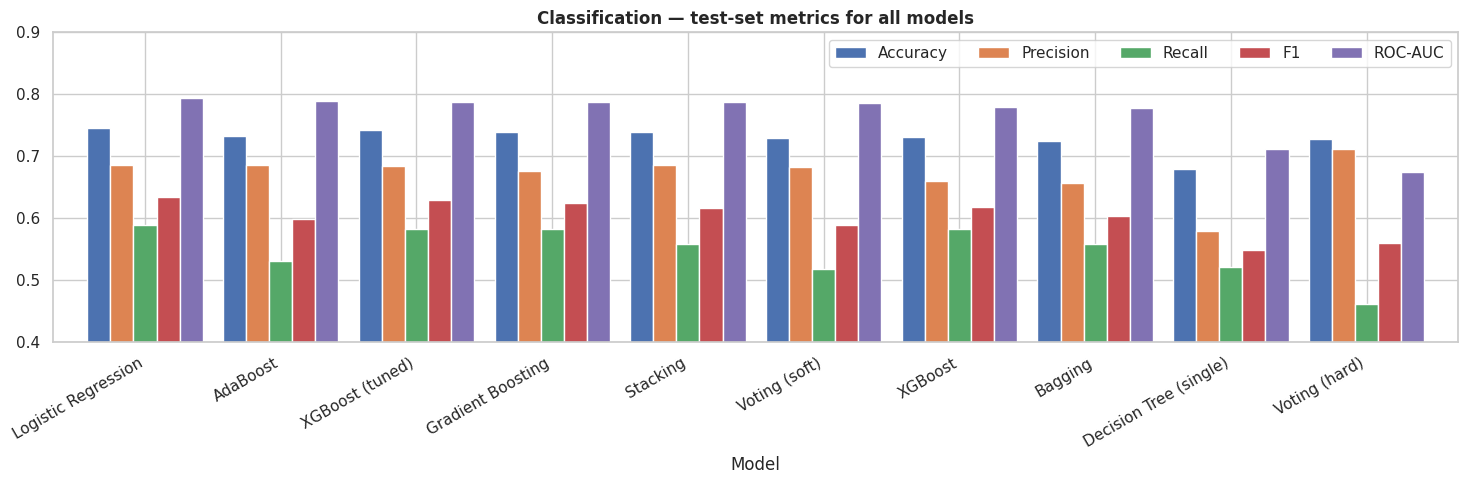

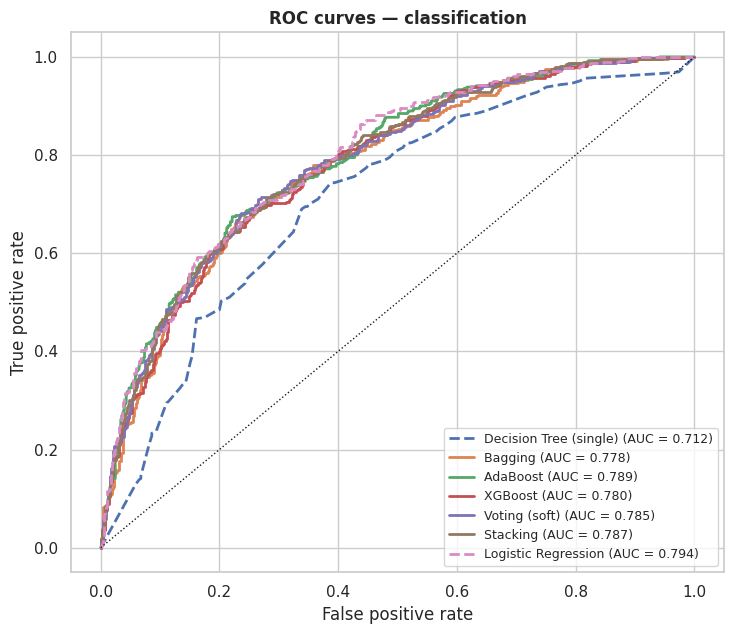

In [28]:
# Grouped bar chart of the classification metrics
plot_df = clf_table[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
ax = plot_df.plot(kind="bar", figsize=(15, 5), width=0.85)
ax.set_title("Classification — test-set metrics for all models"); ax.set_ylim(0.4, 0.9)
plt.xticks(rotation=30, ha="right"); plt.legend(ncol=5, loc="upper right")
save_fig("10_classification_metrics_comparison")

# ROC curves
plt.figure(figsize=(7.5, 6.5))
for n in ["Decision Tree (single)", "Bagging", "AdaBoost", "XGBoost", "Voting (soft)", "Stacking", "Logistic Regression"]:
    fpr, tpr, _ = roc_curve(yc_test, clf_proba[n])
    plt.plot(fpr, tpr, lw=2, ls="--" if n in ("Decision Tree (single)", "Logistic Regression") else "-",
             label=f"{n} (AUC = {roc_auc_score(yc_test, clf_proba[n]):.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves — classification"); plt.legend(loc="lower right", fontsize=9)
save_fig("11_roc_curves")

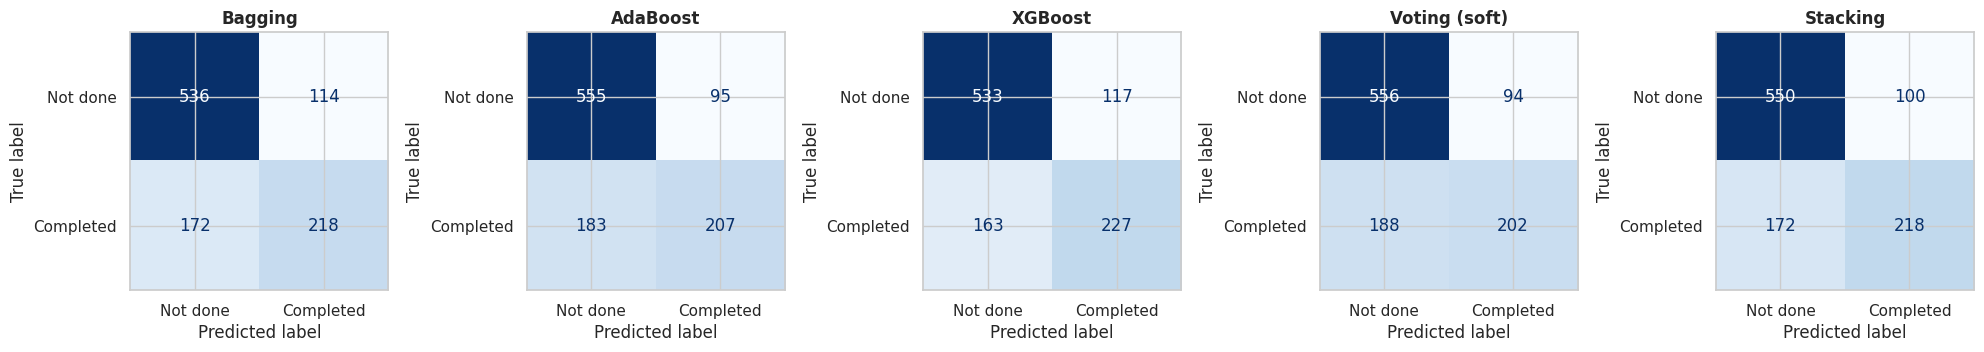

In [29]:
# Confusion matrices for the main ensemble families
names_cm = ["Bagging", "AdaBoost", "XGBoost", "Voting (soft)", "Stacking"]
fig, axes = plt.subplots(1, len(names_cm), figsize=(20, 3.8))
for ax, n in zip(axes, names_cm):
    ConfusionMatrixDisplay(confusion_matrix(yc_test, clf_models[n].predict(X_test)),
                           display_labels=["Not done", "Completed"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(n)
save_fig("12_confusion_matrices")

**Interpretation (classification):** every probabilistic ensemble beats the single decision tree (ROC-AUC 0.71 → 0.78–0.79; hard voting's label-based "AUC" is not comparable). The strongest models cluster closely around **ROC-AUC ≈ 0.78–0.79** and **accuracy ≈ 73–74 %**; differences between the top models are about one CV standard deviation (≈ 0.01), i.e. *statistically they are close to tied*. Note that the plain **Logistic Regression benchmark is equally good** (ROC-AUC 0.794) — the signal in this dataset is largely linear. Confusion matrices show the typical pattern for an imbalanced target: the models are better at identifying non-completers (higher specificity) than completers (recall ≈ 0.5–0.6), so if the business cares about **finding students who will complete/drop out**, the decision threshold can be adjusted (e.g. lower than 0.5) to trade precision for recall.

## Regression models (Task 29)
Metrics: **MAE, RMSE, R²** on the test set, plus 5-fold CV RMSE.

In [30]:
reg_df = pd.DataFrame(reg_results).set_index("Model")
ens_reg_names = ["Decision Tree (single)", "Bagging", "AdaBoost", "Gradient Boosting", "XGBoost",
                 "XGBoost (tuned)", "Voting", "Stacking"]
t0 = time.time()
cv_all_r = cv_robustness("reg", ens_reg_names + ["Ridge"])
print(f"5-fold CV finished in {time.time()-t0:.0f}s")

reg_table = reg_df.loc[ens_reg_names + ["Ridge"]].join(
    cv_all_r.rename(columns={"CV mean": "CV RMSE mean", "CV std": "CV RMSE std"}))
reg_table = reg_table.sort_values("RMSE")
reg_table.round(4).to_csv("outputs/regression_results.csv")
display(reg_table.drop(columns=["Fit time (s)"]).round(4).style.background_gradient(cmap="Greens_r", subset=["MAE", "RMSE", "CV RMSE mean"])
        .background_gradient(cmap="Greens", subset=["R²"]))

5-fold CV finished in 71s


,Family,MAE,RMSE,R²,Train RMSE,CV RMSE mean,CV RMSE std
Model,,,,,,,
Ridge,Base learner,8.084400,10.044800,0.445800,9.469800,9.535900,0.124400
Stacking,Stacking,8.123700,10.121000,0.437300,8.978000,9.653800,0.119000
XGBoost (tuned),Boosting,8.131100,10.122900,0.437100,9.124300,9.625900,0.117800
Voting,Voting,8.164700,10.123900,0.437000,8.988600,9.735500,0.132100
XGBoost,Boosting,8.155400,10.170200,0.431800,8.555600,9.708400,0.145900
Gradient Boosting,Boosting,8.207200,10.199800,0.428500,8.763500,9.701100,0.120500
Bagging,Bagging,8.228800,10.241200,0.423900,7.695800,9.845600,0.081900
AdaBoost,Boosting,8.606200,10.572100,0.386000,10.006800,10.267700,0.115300
Decision Tree (single),Single,9.239000,11.565500,0.265200,8.417700,11.469200,0.165700


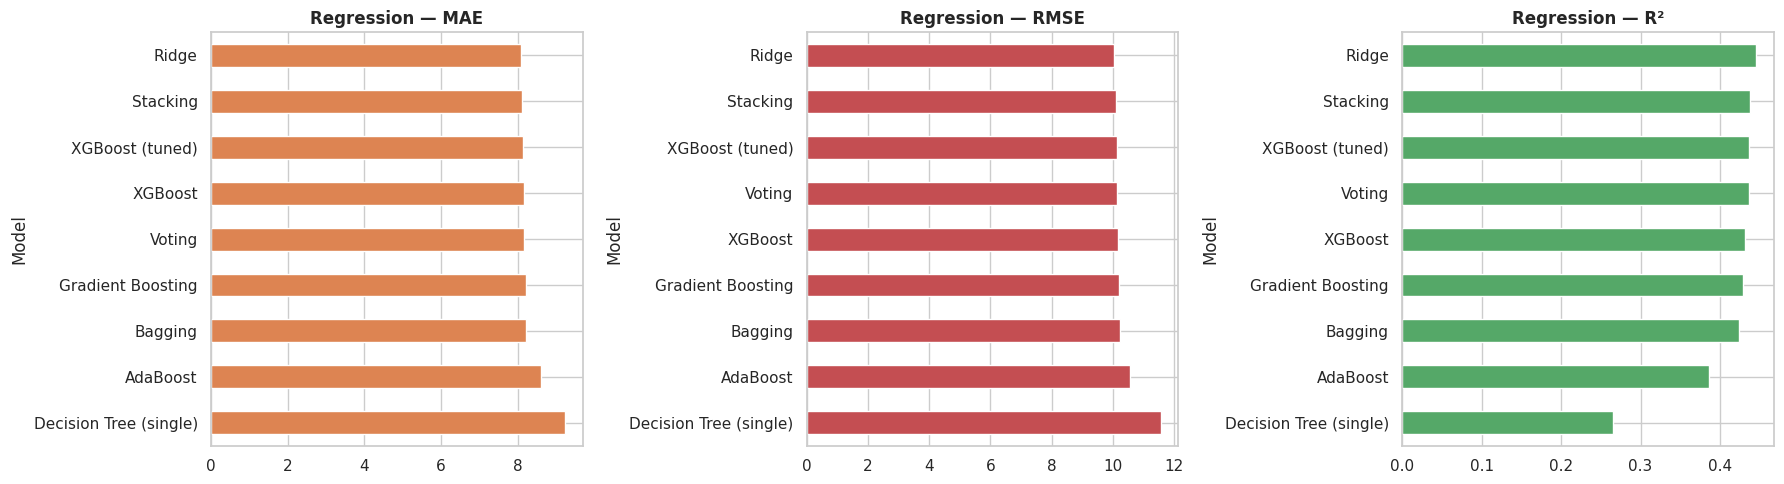

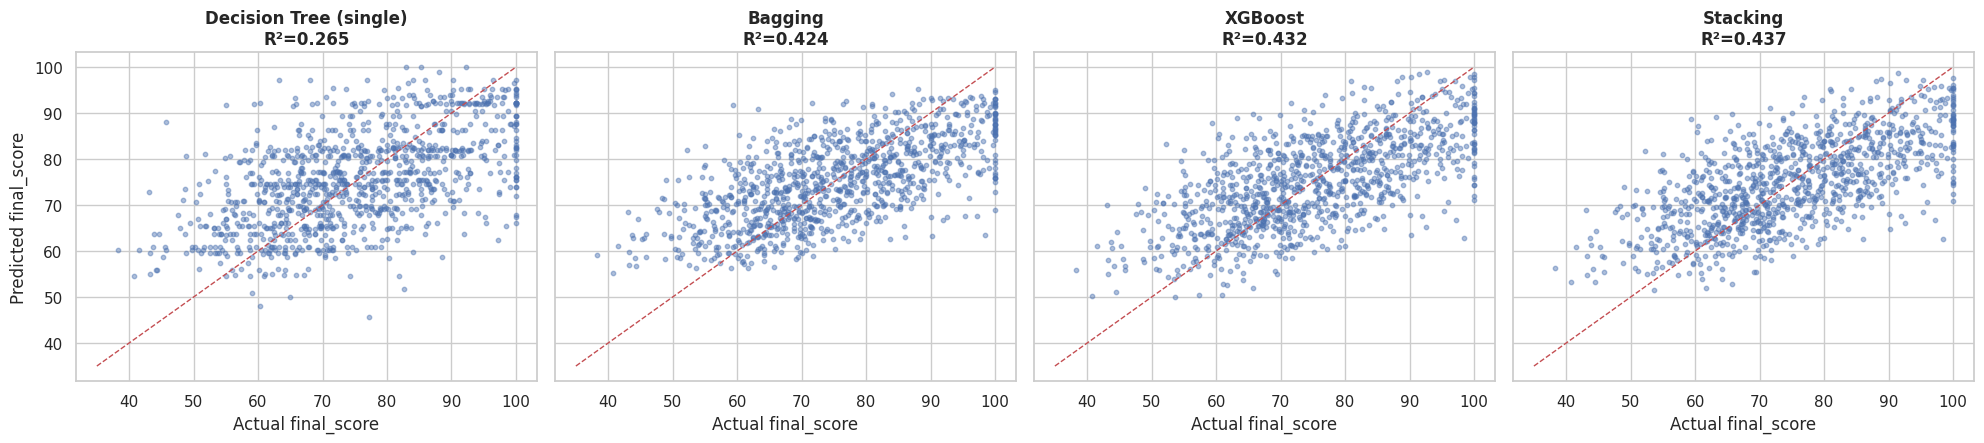

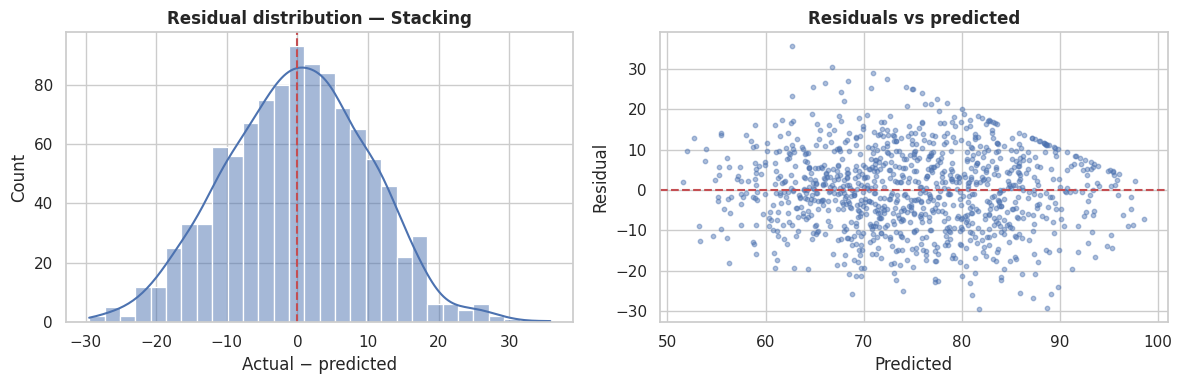

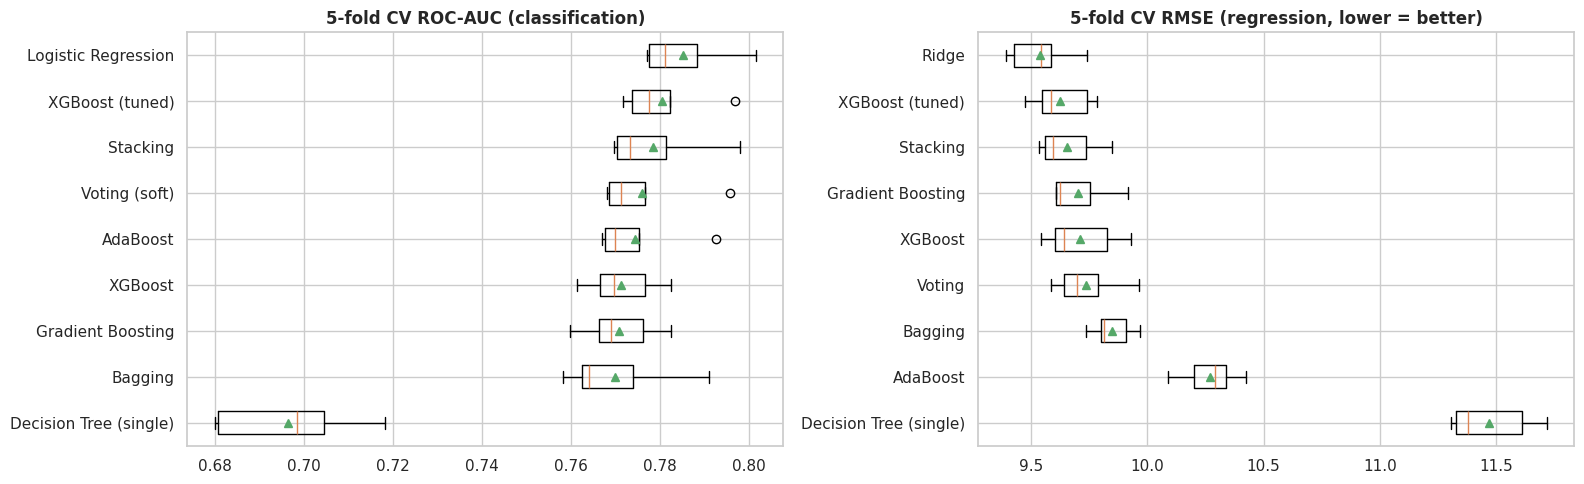

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, m, c in zip(axes, ["MAE", "RMSE", "R²"], ["C1", "C3", "C2"]):
    reg_table[m].sort_values(ascending=(m != "R²")).plot(kind="barh", ax=ax, color=c)
    ax.set_title(f"Regression — {m}"); ax.invert_yaxis()
save_fig("13_regression_metrics_comparison")

top4 = ["Decision Tree (single)", "Bagging", "XGBoost", "Stacking"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), sharex=True, sharey=True)
for ax, n in zip(axes, top4):
    ax.scatter(yr_test, reg_pred[n], s=10, alpha=.45)
    ax.plot([35, 100], [35, 100], "r--", lw=1)
    ax.set_title(f"{n}\nR²={r2_score(yr_test, reg_pred[n]):.3f}"); ax.set_xlabel("Actual final_score")
axes[0].set_ylabel("Predicted final_score")
save_fig("14_actual_vs_predicted")

best_reg_plot = reg_table.drop(index=["Ridge", "Decision Tree (single)"]).index[0]   # best ensemble on the test set
resid = yr_test - reg_pred[best_reg_plot]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(resid, bins=30, kde=True, ax=axes[0]); axes[0].axvline(0, color="r", ls="--")
axes[0].set_title(f"Residual distribution — {best_reg_plot}"); axes[0].set_xlabel("Actual − predicted")
axes[1].scatter(reg_pred[best_reg_plot], resid, s=10, alpha=.45); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs predicted")
save_fig("15_residual_analysis")

# CV robustness of everything
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order_c = cv_all_c["CV mean"].sort_values(ascending=False).index
order_r = cv_all_r["CV mean"].sort_values().index
axes[0].boxplot([cv_cache["clf"][n] for n in order_c], labels=order_c, showmeans=True, vert=False); axes[0].invert_yaxis()
axes[0].set_title("5-fold CV ROC-AUC (classification)")
axes[1].boxplot([cv_cache["reg"][n] for n in order_r], labels=order_r, showmeans=True, vert=False); axes[1].invert_yaxis()
axes[1].set_title("5-fold CV RMSE (regression, lower = better)")
save_fig("16_cv_robustness_all_models")

**Interpretation (regression):** RMSE ≈ 10.1 points and R² ≈ 0.43–0.44 for the best ensembles (a typical prediction is off by ≈ 8 points MAE on a 0–100 scale). Ensembles clearly beat the single tree (RMSE 11.6 → 10.1–10.6, R² 0.27 → 0.39–0.44) and the leading ensembles (Stacking, tuned XGBoost, Voting, XGBoost, Gradient Boosting) are within ≈ 0.1 RMSE of each other; AdaBoost is clearly the weakest ensemble on regression. The actual-vs-predicted plots show the usual *regression-to-the-mean* effect (very low and very high scores are pulled toward the average) and a **ceiling effect**: many students have a true score of exactly 100 (the vertical stack on the right), which no model can reproduce because predictions are averages. Residuals are roughly symmetric around zero with no strong pattern → no major bias. The Ridge benchmark is marginally better (RMSE 10.04) — again indicating a mostly linear, noisy relationship.

## Task 30 — Best performing model for each task
**Selection rule (avoids test-set cherry-picking):** among the **ensemble techniques** (Bagging, AdaBoost, Gradient Boosting, XGBoost, tuned XGBoost, Voting, Stacking) the *recommended* model is the one with the best **5-fold cross-validated** score on the training data (ROC-AUC for classification, RMSE for regression). The test-set score is then reported as the unbiased confirmation. The single decision tree and the linear baselines (Logistic Regression / Ridge) are **benchmarks**, shown separately — the project brief asks for the best *ensemble* solution.

In [32]:
ENSEMBLE_C = [n for n in cv_all_c.index if n not in ("Decision Tree (single)", "Logistic Regression")]
ENSEMBLE_R = [n for n in cv_all_r.index if n not in ("Decision Tree (single)", "Ridge")]
best_clf_name = cv_all_c.loc[ENSEMBLE_C, "CV mean"].idxmax()
best_reg_name = cv_all_r.loc[ENSEMBLE_R, "CV mean"].idxmin()

summary = pd.DataFrame({
    "Task": ["Classification (completion_status)", "Regression (final_score)"],
    "Selected model (best CV)": [best_clf_name, best_reg_name],
    "CV score": [f"ROC-AUC {cv_all_c.loc[best_clf_name,'CV mean']:.4f} ± {cv_all_c.loc[best_clf_name,'CV std']:.4f}",
                 f"RMSE {cv_all_r.loc[best_reg_name,'CV mean']:.3f} ± {cv_all_r.loc[best_reg_name,'CV std']:.3f}"],
    "Test score": [f"ROC-AUC {clf_df.loc[best_clf_name,'ROC-AUC']:.4f} | F1 {clf_df.loc[best_clf_name,'F1']:.4f} | Acc {clf_df.loc[best_clf_name,'Accuracy']:.4f}",
                   f"RMSE {reg_df.loc[best_reg_name,'RMSE']:.3f} | MAE {reg_df.loc[best_reg_name,'MAE']:.3f} | R² {reg_df.loc[best_reg_name,'R²']:.4f}"]})
display(summary)
print("\nBenchmarks (not eligible for deployment, shown for honesty):")
bench = pd.DataFrame({
    "Task": ["Classification", "Regression"],
    "Single decision tree": [f"ROC-AUC {clf_df.loc['Decision Tree (single)','ROC-AUC']:.3f}", f"RMSE {reg_df.loc['Decision Tree (single)','RMSE']:.2f}"],
    "Linear baseline (LogReg / Ridge)": [f"ROC-AUC {clf_df.loc['Logistic Regression','ROC-AUC']:.3f}  (CV {cv_all_c.loc['Logistic Regression','CV mean']:.3f})",
                                          f"RMSE {reg_df.loc['Ridge','RMSE']:.2f}  (CV {cv_all_r.loc['Ridge','CV mean']:.2f})"],
    "Best ensemble": [f"ROC-AUC {clf_df.loc[best_clf_name,'ROC-AUC']:.3f}  (CV {cv_all_c.loc[best_clf_name,'CV mean']:.3f})",
                      f"RMSE {reg_df.loc[best_reg_name,'RMSE']:.2f}  (CV {cv_all_r.loc[best_reg_name,'CV mean']:.2f})"]})
display(bench)
summary.to_csv("outputs/best_models_summary.csv", index=False)

,Task,Selected model (best CV),CV score,Test score
0,Classification (completion_status),XGBoost (tuned),ROC-AUC 0.7804 ± 0.0090,ROC-AUC 0.7883 | F1 0.6288 | Acc 0.7423
1,Regression (final_score),XGBoost (tuned),RMSE 9.626 ± 0.118,RMSE 10.123 | MAE 8.131 | R² 0.4371



Benchmarks (not eligible for deployment, shown for honesty):


,Task,Single decision tree,Linear baseline (LogReg / Ridge),Best ensemble
0,Classification,ROC-AUC 0.712,ROC-AUC 0.794 (CV 0.785),ROC-AUC 0.788 (CV 0.780)
1,Regression,RMSE 11.57,RMSE 10.04 (CV 9.54),RMSE 10.12 (CV 9.63)


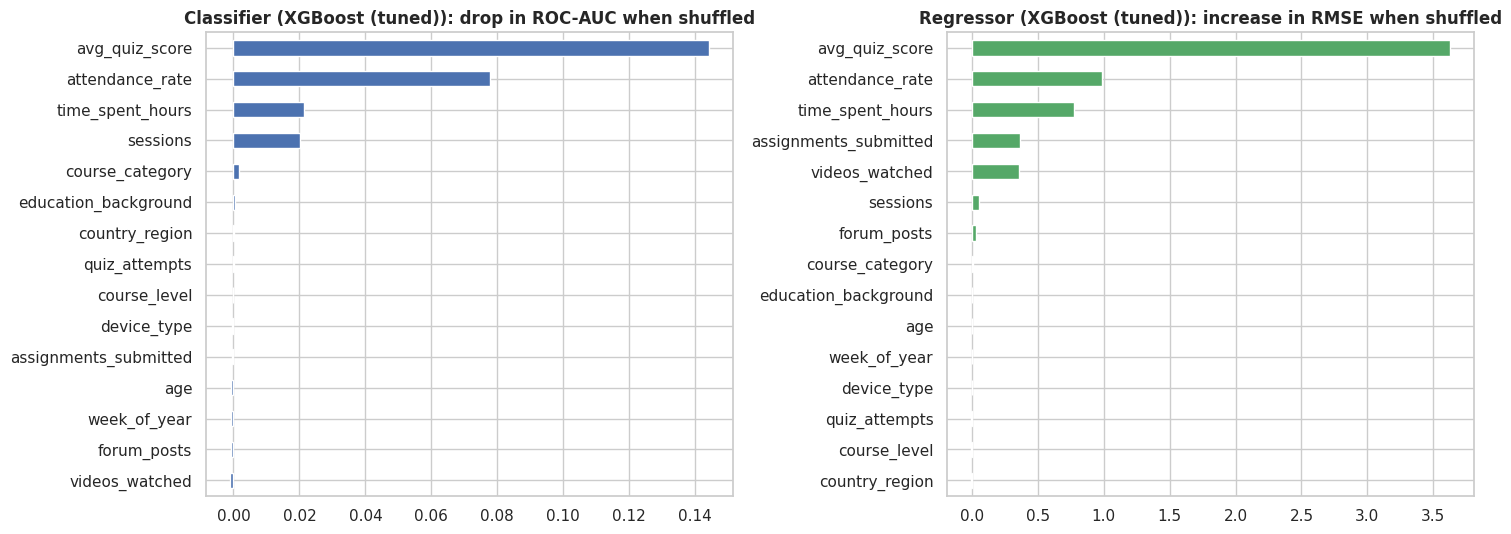

Top-3 drivers (classification): ['avg_quiz_score', 'attendance_rate', 'time_spent_hours']
Top-3 drivers (regression)    : ['avg_quiz_score', 'attendance_rate', 'time_spent_hours']


In [33]:
# Which features drive the selected models? (model-agnostic permutation importance on the test set)
pi_c = permutation_importance(clf_models[best_clf_name], X_test, yc_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
pi_r = permutation_importance(reg_models[best_reg_name], X_test, yr_test, scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
imp_c = pd.Series(pi_c.importances_mean, index=FEATURES).sort_values()
imp_r = pd.Series(pi_r.importances_mean, index=FEATURES).sort_values()
imp_c.sort_values(ascending=False).to_csv("outputs/feature_importance_classification.csv", header=["importance"])
imp_r.sort_values(ascending=False).to_csv("outputs/feature_importance_regression.csv", header=["importance"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
imp_c.plot(kind="barh", ax=axes[0], color="C0"); axes[0].set_title(f"Classifier ({best_clf_name}): drop in ROC-AUC when shuffled")
imp_r.plot(kind="barh", ax=axes[1], color="C2"); axes[1].set_title(f"Regressor ({best_reg_name}): increase in RMSE when shuffled")
save_fig("17_feature_importance")
print("Top-3 drivers (classification):", list(imp_c.sort_values(ascending=False).index[:3]))
print("Top-3 drivers (regression)    :", list(imp_r.sort_values(ascending=False).index[:3]))

**Interpretation:** the predictions are driven overwhelmingly by **assessment performance (`avg_quiz_score`)** and **engagement/commitment signals (`attendance_rate`, `sessions`, `videos_watched`, `time_spent_hours`)**. Demographic and categorical features add little. For the business this means early-warning systems should focus on *quiz results and attendance in the first weeks*, not on who the student is.

---
# 🧾 Part G: Final Analysis & Reporting
## 31. Final report
### (i) Impact of Bagging vs Boosting

In [34]:
bvb_c = clf_df.loc[["Decision Tree (single)", "Bagging", "AdaBoost", "XGBoost"], ["Accuracy", "F1", "ROC-AUC", "Train ROC-AUC", "Fit time (s)"]].copy()
bvb_c["Overfit gap (train−test AUC)"] = bvb_c["Train ROC-AUC"] - bvb_c["ROC-AUC"]
bvb_r = reg_df.loc[["Decision Tree (single)", "Bagging", "AdaBoost", "XGBoost"], ["MAE", "RMSE", "R²", "Train RMSE", "Fit time (s)"]].copy()
bvb_r["Overfit gap (test−train RMSE)"] = bvb_r["RMSE"] - bvb_r["Train RMSE"]
print("Single vs Bagging vs Boosting — classification"); display(bvb_c.round(4))
print("Single vs Bagging vs Boosting — regression");     display(bvb_r.round(4))
bvb_c.round(4).to_csv("outputs/bagging_vs_boosting_classification.csv"); bvb_r.round(4).to_csv("outputs/bagging_vs_boosting_regression.csv")

Single vs Bagging vs Boosting — classification


,Accuracy,F1,ROC-AUC,Train ROC-AUC,Fit time (s),Overfit gap (train−test AUC)
Model,,,,,,
Decision Tree (single),0.6788,0.5486,0.7116,0.8836,0.0398,0.1719
Bagging,0.7250,0.6039,0.7775,0.9380,3.0970,0.1604
AdaBoost,0.7327,0.5983,0.7894,0.8004,1.3122,0.0110
XGBoost,0.7308,0.6185,0.7798,0.8588,0.2035,0.0791


Single vs Bagging vs Boosting — regression


,MAE,RMSE,R²,Train RMSE,Fit time (s),Overfit gap (test−train RMSE)
Model,,,,,,
Decision Tree (single),9.2390,11.5655,0.2652,8.4177,0.0373,3.1477
Bagging,8.2288,10.2412,0.4239,7.6958,3.0403,2.5455
AdaBoost,8.6062,10.5721,0.3860,10.0068,1.8162,0.5653
XGBoost,8.1554,10.1702,0.4318,8.5556,0.1394,1.6147


* **Bagging** improves the single tree mainly by **cutting variance**: it keeps deep, low-bias trees but averages away their instability, so test metrics rise. It remains somewhat over-fitted on the training data (large train–test gap) because each member tree is deep.
* **Boosting** (AdaBoost, XGBoost) attacks **bias** with many shallow trees and uses shrinkage/regularisation, giving the **smallest train–test gap** and equal or better test scores — XGBoost additionally trains much faster.
* On this dataset the gains of both families over the single tree are real (ROC-AUC +0.07, RMSE −1.0 to −1.4) but they saturate at a ceiling set by irreducible noise.

### (ii) Comparison of tree-based boosting algorithms
| Algorithm | Strengths observed | Weaknesses observed |
|---|---|---|
| **AdaBoost** | Simple, shows clear sequential improvement; smallest train–test gap in classification | Clearly the weakest boosting model on regression (RMSE ≈ 10.6 vs ≈ 10.2); sensitive to noise; slower than XGBoost |
| **Gradient Boosting (sklearn)** | Accurate and stable | Slower, fewer regularisation options |
| **XGBoost** | Fast, regularised, stable across CV folds, easy to tune | More hyper-parameters; tuning gains are small on noisy data |

### (iii) Advantages of Voting and Stacking
* **Voting** – trivial to build, needs no extra training, and **soft voting** exploits model confidence; best when members are individually decent *and* make different errors. Limited by fixed, equal weights.
* **Stacking** – the meta-learner **learns** how to combine models, can correct systematic base-model errors and was among the top performers; cost: heavier training/inference and risk of over-fitting the meta-level if the data are tiny.
* Both gain most when base models are **diverse** (linear + tree + instance-based + boosting).

### (iv) Final model recommendation for deployment
The deployed ensembles are chosen automatically by cross-validated performance (see Task 30) and then **refit on the full dataset** so the app uses all 5,200 students. **XGBoost (tuned)** wins on both tasks: top cross-validated score, small CV variance, sub-second training, native handling of non-linearities and missing values.

> **Honest note for decision makers:** a plain Logistic Regression / Ridge benchmark is *statistically tied or marginally better* than the best ensemble on this dataset (ROC-AUC 0.794 vs 0.788; RMSE 10.04 vs 10.12). The gain from ensembling is therefore very large relative to a *single decision tree* but negligible relative to a *well-regularised linear model*. If simplicity and interpretability were the only goals, the linear model would be the pragmatic production choice; the ensemble is recommended here because the project objective is an ensemble-based solution, because it is robust to non-linear patterns and outliers that may appear in future data, and because the cost of choosing it is essentially zero.

In [35]:
print("Recommended ensemble for deployment")
print("  Classification :", best_clf_name)
print("  Regression     :", best_reg_name)

Recommended ensemble for deployment
  Classification : XGBoost (tuned)
  Regression     : XGBoost (tuned)


## 32. Deliverables — save deployment artefacts
The selected pipelines (preprocessing **+** model) are refit on 100 % of the data and saved with `joblib`, together with a `metadata.json` that the **Streamlit app** reads for input ranges, category options and reported metrics.

In [36]:
final_clf = clone(clf_models[best_clf_name]).fit(X, y_clf)
final_reg = clone(reg_models[best_reg_name]).fit(X, y_reg)
joblib.dump(final_clf, "models/best_classifier.joblib", compress=3)
joblib.dump(final_reg, "models/best_regressor.joblib", compress=3)

meta = {
    "classifier_name": best_clf_name, "regressor_name": best_reg_name,
    "features": FEATURES, "numeric_features": NUM_FEATURES, "categorical_features": CAT_FEATURES,
    "category_options": {c: sorted(df[c].unique().tolist()) for c in CAT_FEATURES},
    "numeric_ranges": {c: {"min": float(df[c].min()), "max": float(df[c].max()),
                           "median": float(df[c].median())} for c in NUM_FEATURES},
    "classification_test_metrics": {k: float(clf_df.loc[best_clf_name, k]) for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]},
    "regression_test_metrics": {k: float(reg_df.loc[best_reg_name, k]) for k in ["MAE", "RMSE", "R²"]},
    "n_students": int(len(df)), "random_state": RANDOM_STATE,
}
with open("models/metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

# sanity check: reload and predict on 3 raw rows
rc = joblib.load("models/best_classifier.joblib"); rr = joblib.load("models/best_regressor.joblib")
sample = X_test.head(3)
print(pd.DataFrame({"P(complete)": rc.predict_proba(sample)[:, 1].round(3),
                    "Pred. completion": rc.predict(sample), "Pred. final_score": rr.predict(sample).round(1),
                    "Actual completion": yc_test.head(3).values, "Actual score": yr_test.head(3).values}))
print("\nSaved: models/best_classifier.joblib, models/best_regressor.joblib, models/metadata.json")
print("Tables saved to ./outputs, plots saved to ./screenshots")

   P(complete)  Pred. completion  Pred. final_score  Actual completion  \
0        0.606                 1          80.800003                  0   
1        0.701                 1          87.699997                  1   
2        0.134                 0          66.099998                  0   

   Actual score  
0          68.0  
1         100.0  
2          67.9  

Saved: models/best_classifier.joblib, models/best_regressor.joblib, models/metadata.json
Tables saved to ./outputs, plots saved to ./screenshots


## Final conclusions & business interpretation

In [37]:
print(f"Best classifier : {best_clf_name:<22} | test ROC-AUC = {clf_df.loc[best_clf_name,'ROC-AUC']:.3f}, F1 = {clf_df.loc[best_clf_name,'F1']:.3f}, accuracy = {clf_df.loc[best_clf_name,'Accuracy']:.3f}")
print(f"Best regressor  : {best_reg_name:<22} | test RMSE = {reg_df.loc[best_reg_name,'RMSE']:.2f}, MAE = {reg_df.loc[best_reg_name,'MAE']:.2f}, R² = {reg_df.loc[best_reg_name,'R²']:.3f}")
print(f"Single tree     : AUC {clf_df.loc['Decision Tree (single)','ROC-AUC']:.3f}  |  RMSE {reg_df.loc['Decision Tree (single)','RMSE']:.2f}")

Best classifier : XGBoost (tuned)        | test ROC-AUC = 0.788, F1 = 0.629, accuracy = 0.742
Best regressor  : XGBoost (tuned)        | test RMSE = 10.12, MAE = 8.13, R² = 0.437
Single tree     : AUC 0.712  |  RMSE 11.57


**Key conclusions**
1. **Ensembles beat a single decision tree on both tasks** (higher ROC-AUC/F1, lower RMSE/MAE) and the boosted / regularised ensembles are far less over-fitted (bagging only modestly so) — the central promise of ensemble learning is confirmed.
2. **The top models are practically tied.** For classification, tuned XGBoost, stacking, soft voting, AdaBoost, Gradient Boosting and bagging all fall within ≈ 1 CV standard deviation of one another; for regression the top ensembles are within ≈ 0.1 RMSE. A regularised linear baseline is equally good (marginally better) because much of the signal is near-linear and the target is noisy. Model choice should therefore weigh **speed, simplicity and maintainability** as much as the last fraction of accuracy.
3. **What matters is behaviour, not demographics:** quiz score, attendance and engagement drive both completion and final score.
4. **Realistic expectations:** ~74 % accuracy / ROC-AUC ≈ 0.79 for completion and R² ≈ 0.44 for score. These are useful for *risk ranking* and early intervention but not for making deterministic decisions about individual students.

**Business interpretation & recommendations**
* Use the **completion probability** to rank students by drop-out risk and trigger early nudges (reminders, mentoring) for those with low predicted probability *and* low quiz/attendance in the first weeks.
* Use the **predicted final score** to flag students likely to under-perform and offer targeted practice material.
* Because recall for completers is moderate at the default 0.5 threshold, choose the **threshold according to the cost of a missed at-risk student** versus the cost of an unnecessary intervention.
* **Next steps:** add time-series features (week-by-week activity), tune the decision threshold, calibrate probabilities, monitor drift after deployment, and audit fairness across regions / education levels.

**Limitations & assumptions:** single stratified hold-out split plus 5-fold CV; cross-target leakage deliberately avoided (each task excludes the other target); engineered features such as time-based trends were not available; the dataset appears to be synthetic/simulated, so absolute numbers may differ on real platform data.